# Inside GPT-2: How a Transformer Works, Part by Part
**Group 1 — Transformers Week**

We explore OpenAI's **GPT-2 (small, 124 million parameters)** to see how each part of the transformer works inside a real model, then compare it with the **tiny GPT** our group built from scratch and trained on Kinyarwanda news.

This notebook follows the path a sentence takes through GPT-2:

| # | Part | What it does | Notebook |
|---|---|---|---|
| 1 | Tokens | Splits text into pieces the model can read | `01_tokens_and_generation.ipynb` |
| 2 | Position embedding | Tells the model the order of the tokens | `02_position_embedding.ipynb` |
| 3 | Layer norm | Keeps the numbers at a steady size | `05_layer_norm.ipynb` |
| 4 | Attention | Lets tokens look at each other | `03_attention.ipynb` |
| 5 | Residual connections | Adds each step's result on top of what the token already had | `06_residual_connections.ipynb` |
| 6 | Feed-forward | Lets each token "think" on its own | `04_feed_forward.ipynb` |
| 7 | Text generation | Turns the final numbers into the next word | `01_tokens_and_generation.ipynb` |
| 8 | Tiny GPT vs GPT-2 | What's the same and what's different | — |
| 9 | Try it yourself | GPT-2's top guesses for the next word | — |
| 10 | From GPT-2 to Qwen3 | Repeats our experiments on Qwen3-4B, the model we chose in our LLM blog, plus chat demos and RAG (real documents) | — |
| 11 | Does Sunflower fix Kinyarwanda? | Tests Sunbird AI's Kinyarwanda-trained model on the same sentences, questions and translations | — |
| 12 | RAG with Sunflower | Gives Sunflower real documents and compares all four: Qwen3 and Sunflower, with and without RAG | — |

Each section contains only the **key experiment** from each member's notebook. The full work is in the individual notebooks in `notebooks/`.

**How to run:** turn on the GPU (*Runtime → Change runtime type → T4 GPU*), then *Runtime → Run all*. Or run up to the end of Section 10 first, check the results and the Qwen3 chat boxes, then continue with Section 11 (*Runtime → Run after*). Results that use randomness may differ slightly from the individual notebooks.

## Setup
We load GPT-2 once and define the two example sentences everyone used: the same meaning in English and Kinyarwanda.

In [1]:
!pip install -q transformers

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from contextlib import contextmanager
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained(
    "gpt2",
    output_attentions=True,         # lets us look at attention weights
    output_hidden_states=True,      # lets us look at the numbers after each layer
    attn_implementation="eager",    # needed so attention weights can be returned
).to(device)
model.eval()

print("Device:", device)
print(f"GPT-2 loaded: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} million parameters")

english = "The people of Kicukiro say they have not had water for three days."
kinyarwanda = "Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta mazi bafite."

def compute_loss(text, m=None, **kwargs):
    """How surprised the model is by a sentence (lower = better at predicting it)."""
    m = m or model
    enc = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        return m(**enc, labels=enc["input_ids"], **kwargs).loss.item()

print(f"\nLoss on English sentence:     {compute_loss(english):.2f}")
print(f"Loss on Kinyarwanda sentence: {compute_loss(kinyarwanda):.2f}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Device: cuda
GPT-2 loaded: 124 million parameters


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



Loss on English sentence:     4.46
Loss on Kinyarwanda sentence: 7.35


GPT-2 finds the Kinyarwanda sentence much harder to predict than the English one (a higher loss), because it was trained almost only on English text. We'll see why in the first section.

## 1. Tokens: splitting text into pieces
*From `01_tokens_and_generation.ipynb`*

GPT-2 doesn't read whole words. It splits text into **tokens**, pieces of words it learned from English text. It has about 50,000 of them. Common English words are usually one token, but unfamiliar words get chopped into several pieces.

In [2]:
rows = []
for name, s in [("English", english), ("Kinyarwanda", kinyarwanda)]:
    n_tokens = len(tokenizer.encode(s))
    n_words = len(s.split())
    rows.append({"language": name, "words": n_words, "tokens": n_tokens,
                 "tokens per word": round(n_tokens / n_words, 2)})
display(pd.DataFrame(rows))
print(f"Kinyarwanda needs {rows[1]['tokens'] / rows[0]['tokens']:.2f}x as many tokens as English.\n")

print("The same word in both languages:")
for en, rw in [("water", "amazi"), ("three", "itatu"), ("days", "iminsi"), ("say", "bavuga")]:
    print(f"{en:>8}: {tokenizer.tokenize(' ' + en)}")
    print(f"{rw:>8}: {tokenizer.tokenize(' ' + rw)}")

,language,words,tokens,tokens per word
0,English,13,17,1.31
1,Kinyarwanda,12,29,2.42


Kinyarwanda needs 1.71x as many tokens as English.

The same word in both languages:
   water: ['Ġwater']
   amazi: ['Ġam', 'azi']
   three: ['Ġthree']
   itatu: ['Ġit', 'atu']
    days: ['Ġdays']
  iminsi: ['Ġim', 'ins', 'i']
     say: ['Ġsay']
  bavuga: ['Ġb', 'av', 'uga']


**What we found:** English words like "water" are a single token, but Kinyarwanda words are chopped into pieces ("amazi" → "am" + "azi"). The Kinyarwanda sentence needs about **1.7× as many tokens**, which partly explains why GPT-2 handles it so badly.

**Compared with our tiny GPT:** our tiny GPT used single **characters** as tokens: just **78** (letters, digits and punctuation), compared with GPT-2's ~50,000 word pieces. Every Kinyarwanda word is spelled out letter by letter, so it never has this splitting problem, but it has to learn spelling from scratch.

## 2. Position embedding: knowing the order
*From `02_position_embedding.ipynb`*

Attention looks at all tokens at once, so on its own it doesn't know which token came first. GPT-2 fixes this with a **position embedding**: a learned table with one set of 768 numbers for each of its 1,024 positions, added to each token's numbers.

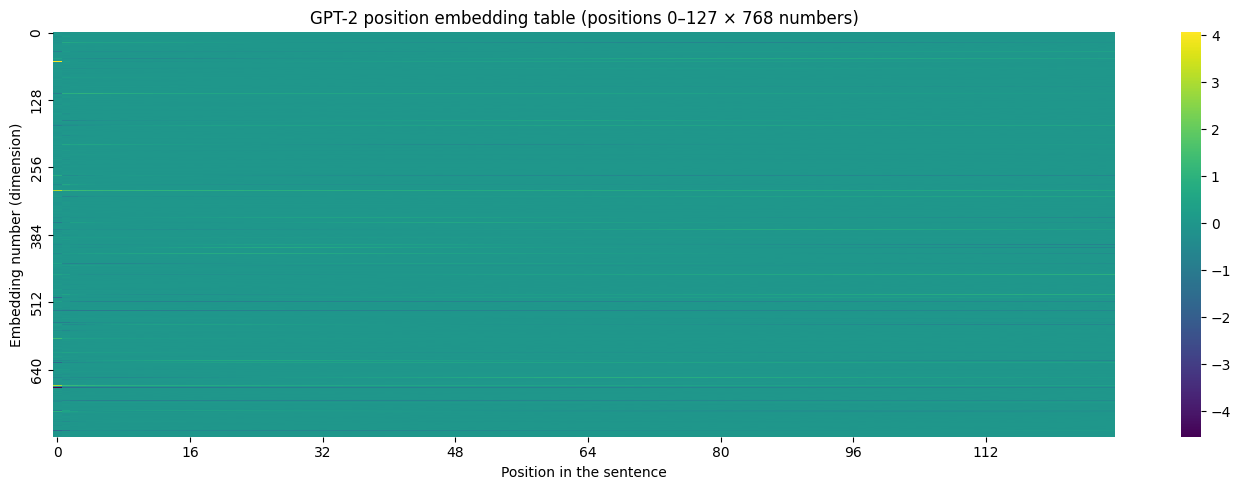

In [3]:
pos_embedding_matrix = model.transformer.wpe.weight.detach().cpu().numpy()

plt.figure(figsize=(14, 5))
sns.heatmap(pos_embedding_matrix[:128, :].T, cmap="viridis", cbar=True,
            xticklabels=16, yticklabels=128)
plt.title("GPT-2 position embedding table (positions 0–127 × 768 numbers)")
plt.xlabel("Position in the sentence")
plt.ylabel("Embedding number (dimension)")
plt.tight_layout()
plt.show()

Position 0 stands out with its own distinct pattern (a strong "start of text" signal), while neighbouring positions look similar to each other, so the representation changes gradually from one position to the next.

**Experiment:** keep the words exactly the same and in the same order, but scramble the **position numbers** GPT-2 receives. If the loss rises, GPT-2 really depends on the position embedding.

In [4]:
inputs = tokenizer(english, return_tensors="pt").to(device)
n = inputs["input_ids"].shape[1]
normal_loss = compute_loss(english)

scrambled_losses = []
for seed in range(5):
    torch.manual_seed(seed)
    perm = torch.randperm(n, device=device).unsqueeze(0)
    scrambled_losses.append(compute_loss(english, position_ids=perm))

print(f"Loss with correct positions:   {normal_loss:.2f}")
print(f"Loss with scrambled positions: {[round(l, 2) for l in scrambled_losses]}")
print(f"Average scrambled loss:        {np.mean(scrambled_losses):.2f}")

Loss with correct positions:   4.46
Loss with scrambled positions: [9.56, 8.3, 9.99, 10.6, 10.31]
Average scrambled loss:        9.75


**What we found:** with the positions scrambled, the loss roughly **doubles**, even though the words themselves are correct. GPT-2 relies heavily on the position embedding to understand the sentence.

**Compared with our tiny GPT:** our tiny GPT used exactly the same idea, a learned position table, but with only **64 positions** (64 characters, roughly 10 words) instead of GPT-2's 1,024 tokens, so it can only look back a short distance.

## 3. Layer norm: keeping the numbers steady
*From `05_layer_norm.ipynb`*

Each of GPT-2's 12 blocks has two layer norms (`ln_1` before attention, `ln_2` before feed-forward), plus one final layer norm: **25 in total**. Layer norm rescales each token's numbers to a steady range before each step.

**Experiment:** measure the size of each token's numbers going into and coming out of `ln_1`, in all 12 blocks.

Layer | size before LN | size after LN
    0 |            5.1 |           2.9
    1 |           54.5 |           4.1
    2 |           56.2 |           7.7
    3 |           60.9 |           9.5
    4 |           66.6 |           8.9
    5 |           72.4 |          10.6
    6 |           78.8 |           9.9
    7 |           89.2 |           9.9
    8 |          104.6 |           9.2
    9 |          126.3 |           8.9
   10 |          159.7 |           8.3
   11 |          245.6 |           7.7


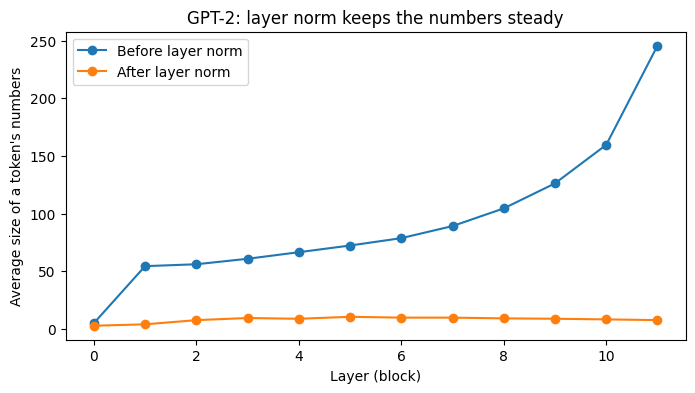

First token's size before layer norm, per layer: [10, 133, 636, 2564, 2748, 2897, 2991, 3046, 3080, 3101, 3111, 3112]


In [5]:
before, after, first_token = [], [], []

def make_hook():
    def hook(module, inp, outp):
        b, a = inp[0][0], outp[0]
        before.append(b[1:].norm(dim=-1).mean().item())   # average size, skipping the first token
        after.append(a[1:].norm(dim=-1).mean().item())
        first_token.append(b[0].norm().item())            # first token measured separately
    return hook

hooks = [block.ln_1.register_forward_hook(make_hook()) for block in model.transformer.h]
with torch.no_grad():
    model(**inputs)
for h in hooks:
    h.remove()

print("Layer | size before LN | size after LN")
for i in range(12):
    print(f"{i:5} | {before[i]:14.1f} | {after[i]:13.1f}")

plt.figure(figsize=(8, 4))
plt.plot(range(12), before, marker="o", label="Before layer norm")
plt.plot(range(12), after, marker="o", label="After layer norm")
plt.xlabel("Layer (block)")
plt.ylabel("Average size of a token's numbers")
plt.title("GPT-2: layer norm keeps the numbers steady")
plt.legend()
plt.show()

print("First token's size before layer norm, per layer:", [round(v) for v in first_token])

**What we found:** the numbers grow about **48 times** larger from the first block to the last (because residual connections keep adding to each token), but after layer norm they always stay in a small, steady range. The first token grows even more, to over 3,000. This is the "attention sink" token, which also shows up in the attention section.

**Experiment:** what happens if we remove the layer norms?

In [6]:
def continue_text(m, prompt, n=20):
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = m.generate(**enc, max_new_tokens=n, do_sample=False,
                         pad_token_id=tokenizer.eos_token_id,
                         output_attentions=False, output_hidden_states=False)
    return tokenizer.decode(out[0])

no_ln = copy.deepcopy(model)              # a copy, so the original GPT-2 stays untouched
for block in no_ln.transformer.h:
    block.ln_1 = torch.nn.Identity()      # Identity = "do nothing", i.e. layer norm removed
    block.ln_2 = torch.nn.Identity()

print(f"Loss WITH layer norm:    {compute_loss(english):.2f}")
print(f"Loss WITHOUT layer norm: {compute_loss(english, m=no_ln):.2f}")

prompt = "The people of Kicukiro say"
print("\nWITH layer norm:   ", continue_text(model, prompt))
print("WITHOUT layer norm:", continue_text(no_ln, prompt))

del no_ln   # free the memory

Loss WITH layer norm:    4.46
Loss WITHOUT layer norm: nan

WITH layer norm:    The people of Kicukiro say that the city is a place of peace and harmony.

"We are not afraid of the
WITHOUT layer norm: The people of Kicukiro say!!!!!!!!!!!!!!!!!!!!


**What we found:** without layer norm, the loss becomes `nan` ("not a number"): the numbers grow so large that the calculations break, and GPT-2 only writes "!!!!!". GPT-2 was trained with layer norm, so it depends on it completely.

**Compared with our tiny GPT:** our tiny GPT used the same layer norm before attention and feed-forward in each of its **4 blocks** (plus a final one), exactly like GPT-2's design. With 4 blocks instead of 12, the numbers have less room to grow, but the purpose is the same.

## 4. Attention: tokens looking at each other
*From `03_attention.ipynb`*

Attention is the only part of the transformer where tokens share information. GPT-2 has **12 layers × 12 heads = 144 attention heads**. Each head learns its own pattern of what to look at.

**Experiment:** search all 144 heads for clear patterns.

In [7]:
with torch.no_grad():
    attentions = model(**inputs).attentions
input_tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
num_layers, num_heads = len(attentions), attentions[0].shape[1]
print(f"{num_layers} layers x {num_heads} heads, sentence of {len(input_tokens)} tokens\n")

prev_token_scores, first_token_scores = [], []
for layer in range(num_layers):
    layer_attn = attentions[layer][0].cpu().numpy()
    for head in range(num_heads):
        m = layer_attn[head]
        prev_token_scores.append((np.mean([m[i, i - 1] for i in range(1, n)]), layer, head))
        first_token_scores.append((np.mean(m[1:, 0]), layer, head))

prev_token_scores.sort(reverse=True)
first_token_scores.sort(reverse=True)

print("Heads that look at the PREVIOUS token:")
for score, layer, head in prev_token_scores[:3]:
    print(f"  Layer {layer}, Head {head}: {score:.4f}")
print("\nHeads that look at the FIRST token (attention sink):")
for score, layer, head in first_token_scores[:3]:
    print(f"  Layer {layer}, Head {head}: {score:.4f}")

12 layers x 12 heads, sentence of 17 tokens

Heads that look at the PREVIOUS token:
  Layer 4, Head 11: 0.9998
  Layer 2, Head 2: 0.5500
  Layer 3, Head 3: 0.4208

Heads that look at the FIRST token (attention sink):
  Layer 5, Head 1: 0.9989
  Layer 7, Head 2: 0.9975
  Layer 6, Head 9: 0.9966


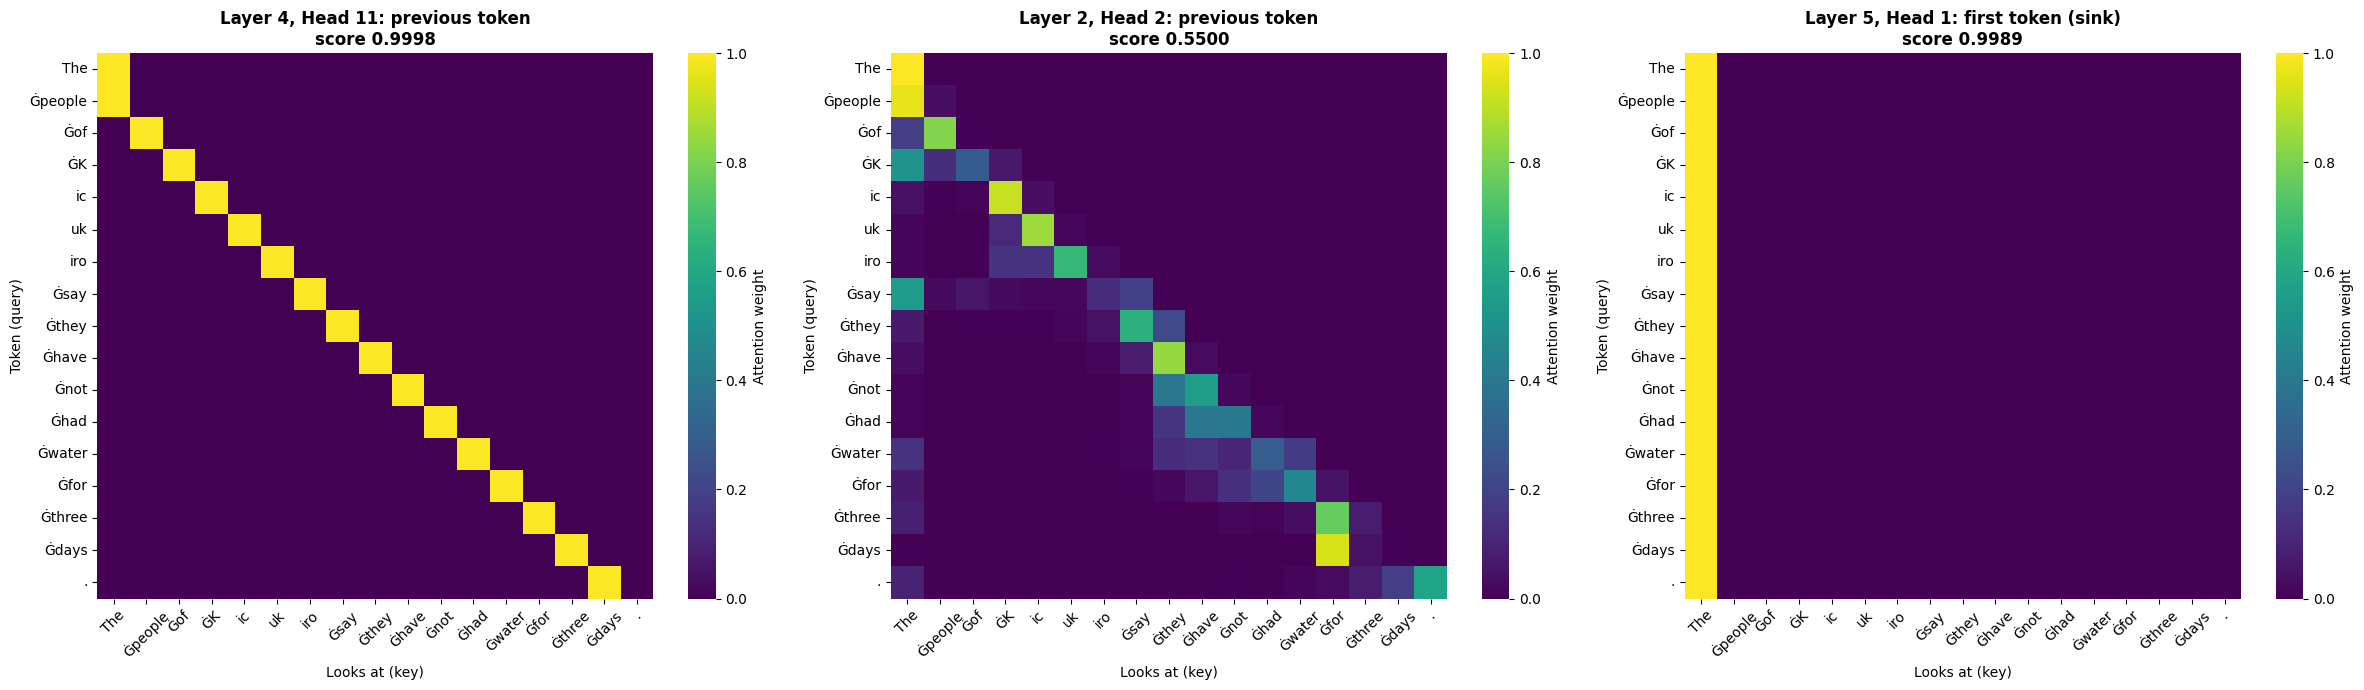

In [8]:
(p_score, p_layer, p_head), (s_score, s_layer, s_head) = prev_token_scores[0], prev_token_scores[1]
f_score, f_layer, f_head = first_token_scores[0]

heads_to_plot = [
    (p_layer, p_head, f"Layer {p_layer}, Head {p_head}: previous token\nscore {p_score:.4f}"),
    (s_layer, s_head, f"Layer {s_layer}, Head {s_head}: previous token\nscore {s_score:.4f}"),
    (f_layer, f_head, f"Layer {f_layer}, Head {f_head}: first token (sink)\nscore {f_score:.4f}"),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (layer, head, title) in zip(axes, heads_to_plot):
    sns.heatmap(attentions[layer][0, head].cpu().numpy(), xticklabels=input_tokens,
                yticklabels=input_tokens, cmap="viridis", ax=ax,
                cbar_kws={"label": "Attention weight"})
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Looks at (key)")
    ax.set_ylabel("Token (query)")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Does the previous-token head behave the same on Kinyarwanda?
rw_inputs = tokenizer(kinyarwanda, return_tensors="pt").to(device)
with torch.no_grad():
    rw_attn = model(**rw_inputs).attentions
rw_n = rw_inputs["input_ids"].shape[1]

for name, attn, length in [("English", attentions, n), ("Kinyarwanda", rw_attn, rw_n)]:
    m = attn[p_layer][0, p_head].cpu().numpy()
    score = np.mean([m[i, i - 1] for i in range(1, length)])
    print(f"{name}: Layer {p_layer}, Head {p_head} previous-token score = {score:.4f} ({length} tokens)")

English: Layer 4, Head 11 previous-token score = 0.9998 (17 tokens)
Kinyarwanda: Layer 4, Head 11 previous-token score = 0.9999 (29 tokens)


**What we found:**
- One head (Layer 4, Head 11) puts almost **100%** of its attention on the **previous token**, and works just as well on Kinyarwanda, where it may help stitch word pieces back together.
- Several middle-layer heads send almost all their attention to the **first token**. This "attention sink" is a resting place for heads with nothing useful to look at, and it connects with the layer norm result, where the first token had huge numbers.

**Compared with our tiny GPT:** our tiny GPT has **4 blocks × 4 heads = 16 attention heads**, each working with 32 numbers. GPT-2 has **144 heads** of 64 numbers each, which gives it room for specialised heads like the ones above.

## 5. Residual connections: adding, not replacing
*From `06_residual_connections.ipynb`*

Each attention and feed-forward step **adds** its result to the token's running total, called the **residual stream**, instead of replacing it. So information builds up layer by layer.

**Experiment ("logit lens"):** give GPT-2 our sentence with the last word removed. After each of the 12 layers, take the residual stream of the last token and ask: *"if GPT-2 stopped here, what word would it predict?"* This lets us watch the prediction form inside the model.

In [10]:
# The shared sentences, with the LAST word removed. The model has to guess that missing word.
english_prompt = "The people of Kicukiro say they have not had water for three"
english_answer = " days"

kiny_prompt = "Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta mazi"
kiny_answer = " bafite"

def residual_stream_lens(prompt, correct_word):
    enc = tokenizer(prompt, return_tensors="pt").to(device)

    # The ID of the correct word's FIRST token (a long word can be split into several tokens,
    # and the model predicts one token at a time).
    correct_id = tokenizer.encode(correct_word)[0]

    # hidden_states = the residual stream after the embeddings and after each of the 12 layers
    with torch.no_grad():
        snapshots = model(**enc).hidden_states
    num_layers = len(model.transformer.h)

    rows = []
    for i, snapshot in enumerate(snapshots):
        vector = snapshot[0, -1]                        # the last token predicts the next word
        if i < num_layers:                              # the last snapshot already has the
            vector = model.transformer.ln_f(vector)     # final layer norm applied
        probs = torch.softmax(model.lm_head(vector), dim=-1)
        top_prob, top_id = probs.max(dim=-1)
        rows.append({
            "stopped after": "embeddings" if i == 0 else f"layer {i}",
            "top guess": repr(tokenizer.decode(top_id)),
            "confidence": f"{top_prob.item():.1%}",
            "chance of correct word": f"{probs[correct_id].item():.2%}",
        })
    return pd.DataFrame(rows)

print("ENGLISH (correct word:", repr(english_answer), ")")
english_table = residual_stream_lens(english_prompt, english_answer)
print(english_table.to_string(index=False))

print("\nKINYARWANDA (correct word:", repr(kiny_answer), ")")
kiny_table = residual_stream_lens(kiny_prompt, kiny_answer)
print(kiny_table.to_string(index=False))

ENGLISH (correct word: ' days' )
stopped after      top guess confidence chance of correct word
   embeddings    ' challeng'      51.6%                  0.00%
      layer 1         'teen'      42.6%                  1.20%
      layer 2         'teen'      32.4%                  0.82%
      layer 3     ' hundred'      26.5%                  1.72%
      layer 4     ' hundred'      37.0%                  1.63%
      layer 5       ' weeks'      27.6%                  1.64%
      layer 6 ' consecutive'      22.7%                  1.94%
      layer 7      ' months'      40.4%                  4.53%
      layer 8      ' months'      36.1%                  2.63%
      layer 9      ' months'      54.9%                  1.93%
     layer 10      ' months'      56.6%                  2.82%
     layer 11      ' months'      39.2%                  9.88%
     layer 12       ' years'      34.1%                 18.04%

KINYARWANDA (correct word: ' bafite' )
stopped after top guess confidence chance of 

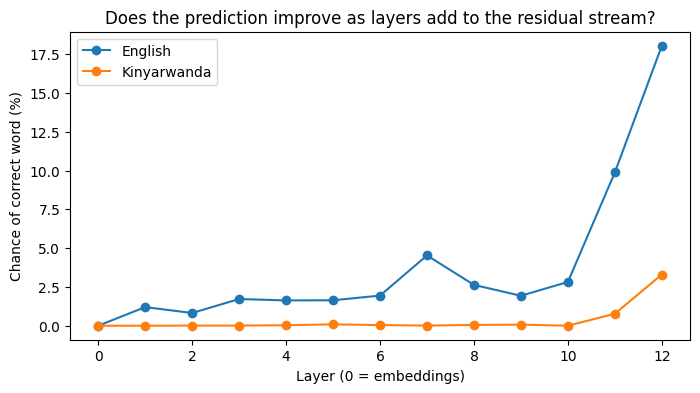

In [11]:
def to_number(col):
    return [float(x.strip("%")) for x in col]

plt.figure(figsize=(8, 4))
plt.plot(to_number(english_table["chance of correct word"]), marker="o", label="English")
plt.plot(to_number(kiny_table["chance of correct word"]), marker="o", label="Kinyarwanda")
plt.xlabel("Layer (0 = embeddings)")
plt.ylabel("Chance of correct word (%)")
plt.title("Does the prediction improve as layers add to the residual stream?")
plt.legend()
plt.show()

**What we found:**
- **English:** the prediction takes shape layer by layer. Early layers guess word fragments, middle layers move to numbers ("hundred"), and from around layer 5 GPT-2 switches to **time words** ("weeks", "months", "years"). The chance of the correct word, "days", grows from **0% to about 18%**. GPT-2's final top guess is "years", but "days" is clearly being built up. Because each layer only *adds* to the stream, earlier understanding ("a time unit comes next") is kept and refined.
- **Kinyarwanda:** the guesses jump between meaningless pieces, and the chance of the correct word stays near zero. Note: "bafite" is split into several tokens, and this test only checks the first piece (" b"), which is very common, so the small rise at the end doesn't mean GPT-2 understood the sentence.

**Compared with our tiny GPT:** our tiny GPT used the same residual connections (`x = x + attention(...)` and `x = x + feed_forward(...)`) in each block. They are what make it possible to stack many blocks without losing the original information.

## 6. Feed-forward: each token thinks on its own
*From `04_feed_forward.ipynb`*

After attention, each token passes through a small neural network on its own: 768 numbers → 3,072 → back to 768. Researchers believe this is where a lot of knowledge and language patterns are stored (Geva et al., 2021).

**Experiment:** switch off the feed-forward part of each layer, one at a time, and see how much worse GPT-2 gets.

Layer  0 | English: +3.7631 | Kinyarwanda: +0.7502
Layer  1 | English: +0.0144 | Kinyarwanda: +0.0812
Layer  2 | English: +0.1479 | Kinyarwanda: +0.0639
Layer  3 | English: +0.0344 | Kinyarwanda: -0.0663
Layer  4 | English: +0.1672 | Kinyarwanda: -0.0756
Layer  5 | English: +0.0295 | Kinyarwanda: -0.0299
Layer  6 | English: +0.0470 | Kinyarwanda: -0.0782
Layer  7 | English: +0.1142 | Kinyarwanda: -0.0578
Layer  8 | English: +0.1607 | Kinyarwanda: +0.0384
Layer  9 | English: +0.1323 | Kinyarwanda: -0.0491
Layer 10 | English: -0.0846 | Kinyarwanda: +0.0177
Layer 11 | English: +0.2623 | Kinyarwanda: +0.7264


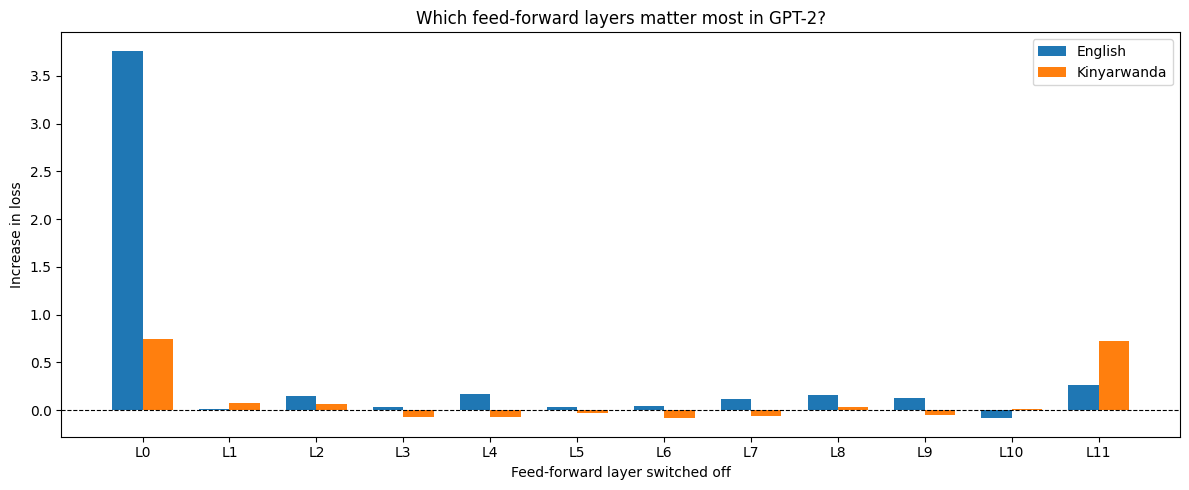

In [12]:
@contextmanager
def mute_mlp(layer_idx):
    """Temporarily replace one layer's feed-forward output with zeros."""
    mlp = model.transformer.h[layer_idx].mlp
    original_forward = mlp.forward
    mlp.forward = lambda *args, **kwargs: torch.zeros_like(original_forward(*args, **kwargs))
    try:
        yield
    finally:
        mlp.forward = original_forward

baseline_eng, baseline_kin = compute_loss(english), compute_loss(kinyarwanda)
eng_increases, kin_increases = [], []
for layer in range(12):
    with mute_mlp(layer):
        eng_increases.append(compute_loss(english) - baseline_eng)
        kin_increases.append(compute_loss(kinyarwanda) - baseline_kin)
    print(f"Layer {layer:2d} | English: {eng_increases[-1]:+.4f} | Kinyarwanda: {kin_increases[-1]:+.4f}")

x = np.arange(12)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - 0.175, eng_increases, 0.35, label="English")
ax.bar(x + 0.175, kin_increases, 0.35, label="Kinyarwanda")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels([f"L{i}" for i in range(12)])
ax.set_xlabel("Feed-forward layer switched off")
ax.set_ylabel("Increase in loss")
ax.set_title("Which feed-forward layers matter most in GPT-2?")
ax.legend()
plt.tight_layout()
plt.show()

**What we found:** switching off **Layer 0** breaks GPT-2 far more than any other layer (+3.76 for English). The last layer (11) also matters, especially for Kinyarwanda. Most middle layers change very little. These results come from one sentence per language, so small differences may just be noise.

**Compared with our tiny GPT:** our tiny GPT used the same design, expanding to 4× the size and shrinking back, but much smaller: **128 → 512 → 128** numbers, compared with GPT-2's 768 → 3,072 → 768. One small difference: it uses the ReLU activation, while GPT-2 uses GELU.

## 7. Text generation: writing the next word
*From `01_tokens_and_generation.ipynb`*

At the end, GPT-2 turns the last token's numbers into a probability for each of its ~50,000 tokens and picks one. **Temperature** controls how adventurous it is: low = safe and repetitive, high = creative and chaotic.

In [13]:
def generate(prompt, temperature, max_new_tokens=40, seed=42):
    torch.manual_seed(seed)   # same seed each time, so only temperature changes
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model.generate(**enc, do_sample=True, temperature=temperature, top_k=0, top_p=1.0,
                             max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id,
                             output_attentions=False, output_hidden_states=False)
    return tokenizer.decode(out[0], skip_special_tokens=True)

for p in ["The people of Kicukiro say", "Abaturage bo mu Kicukiro bavuga ko"]:
    print("=" * 70)
    print("PROMPT:", p)
    for t in [0.2, 0.7, 1.5]:
        print(f"\n--- temperature {t} ---")
        print(generate(p, t))
    print()

PROMPT: The people of Kicukiro say

--- temperature 0.2 ---
The people of Kicukiro say they are not afraid of the police, but they are afraid of the people of Kicukiro.

"We are not afraid of the police. We are afraid of the people of K

--- temperature 0.7 ---
The people of Kicukiro say they are not afraid of being attacked, but they are afraid of being attacked by the mob, because they are scared of the public opinion, because they are afraid of the mob, because they are afraid

--- temperature 1.5 ---
The people of Kicukiro say none the less that protagonist Akira Yen posted nostalgia to storage boxes in hopes spreading it all laugh at Yamonen Nation 6 Internet (TCIIIIKIN WILL YOU PAT That brilliant stall class Kikiamond

PROMPT: Abaturage bo mu Kicukiro bavuga ko

--- temperature 0.2 ---
Abaturage bo mu Kicukiro bavuga ko kunai.

Kunai ko kunai.

Kunai ko kunai.

Kunai ko kunai.

Kunai ko

--- temperature 0.7 ---
Abaturage bo mu Kicukiro bavuga ko ji no ko kunu, siya na ngayon ko k

**What we found:** at low temperature, GPT-2 repeats itself; around 0.7 it writes fluent English; at 1.5 it becomes nonsense. Given a Kinyarwanda prompt, it can't continue properly in Kinyarwanda.

**Compared with our tiny GPT:** our tiny GPT writes Kinyarwanda-looking text because it was trained on Kinyarwanda news. Given the prompt "Ikipe", it wrote: *"Ikipe ye ya Afurika y'ingendo z'ibikorwa n'igitabo gitero cya mbere na Maria Commosiaria waba ari uwarambutse abaturage..."* Many words are real Kinyarwanda, but the sentence doesn't make sense. GPT-2 writes fluent English but can't continue in Kinyarwanda. Size matters, but so does the training data.

## 8. Our tiny GPT vs GPT-2
Both use the **same design**: token embedding + position embedding, then blocks of layer norm → attention → residual → layer norm → feed-forward → residual. The difference is mostly **size** and **training data**.

In [14]:
cfg = model.config
gpt2 = {
    "Tokens": f"word pieces ({cfg.vocab_size:,})",
    "Blocks (layers)": cfg.n_layer,
    "Attention heads per block": cfg.n_head,
    "Total attention heads": cfg.n_layer * cfg.n_head,
    "Numbers per token (embedding size)": cfg.n_embd,
    "Context length": f"{cfg.n_positions} tokens",
    "Parameters": f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} million",
    "Training data": "~40 GB of English web text",
}

tiny_gpt = {   # from our tiny GPT notebook (gpt/Tiny_gpt.ipynb)
    "Tokens": "characters (78)",
    "Blocks (layers)": 4,
    "Attention heads per block": 4,
    "Total attention heads": 16,
    "Numbers per token (embedding size)": 128,
    "Context length": "64 characters",
    "Parameters": "0.82 million",
    "Training data": "~24 million characters of Kinyarwanda news (KINNEWS)",
}

display(pd.DataFrame({"Our tiny GPT": tiny_gpt, "GPT-2 (small)": gpt2}))

,Our tiny GPT,GPT-2 (small)
Tokens,characters (78),"word pieces (50,257)"
Blocks (layers),4,12
Attention heads per block,4,12
Total attention heads,16,144
Numbers per token (embedding size),128,768
Context length,64 characters,1024 tokens
Parameters,0.82 million,124 million
Training data,~24 million characters of Kinyarwanda news (KI...,~40 GB of English web text


**Training:** our tiny GPT trained for 5,000 steps (batches of 64 chunks of 64 characters) and reached a training loss of about **1.40**. This number can't be compared directly with GPT-2's losses above, because our tiny GPT predicts one *character* at a time (78 options), while GPT-2 predicts one *word piece* at a time (~50,000 options).

**In short:** GPT-2 is our tiny GPT scaled up about 150 times and trained on far more text. The design is the same; the size and the training data are what make the difference.

### Key findings
1. **Tokens:** Kinyarwanda needs about 1.7× as many GPT-2 tokens as English, because GPT-2's tokens were learned from English.
2. **Position embedding:** scrambling only the positions roughly doubles the loss, so word order really matters to GPT-2.
3. **Layer norm:** the numbers grow about 48× through the layers; layer norm keeps them steady, and removing it breaks GPT-2 completely.
4. **Attention:** GPT-2 has specialised heads, like one that almost always looks at the previous token, and an "attention sink" on the first token.
5. **Residual connections:** layer by layer, GPT-2 builds its prediction in the residual stream: for English it moves from word fragments to numbers to time words, and the chance of the correct word ("days") grows from 0% to about 18%. For Kinyarwanda it never gets there.
6. **Feed-forward:** the first layer's feed-forward is by far the most important; most middle layers matter little.
7. **Generation and comparison:** same design as our tiny GPT, but about 150× bigger (124 million vs 0.82 million parameters) and trained on English, so it writes fluent English but not Kinyarwanda.

### Sources
- Radford et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2).
- Vaswani et al. (2017). *Attention Is All You Need.* https://arxiv.org/abs/1706.03762
- Geva et al. (2021). *Transformer Feed-Forward Layers Are Key-Value Memories.* https://arxiv.org/abs/2012.14913
- nostalgebraist (2020). *Interpreting GPT: the logit lens.* https://www.lesswrong.com/posts/AcKRB8wDpdaN6v6ru/interpreting-gpt-the-logit-lens
- Hugging Face Transformers documentation: https://huggingface.co/docs/transformers

## 9. Try it yourself: GPT-2 predicting the next word
After looking at each part separately, here is GPT-2 working as a whole. Give it the start of a sentence, and it shows its top 5 guesses for the next word, with how confident it is.

To test your own sentences, only change the text inside the `predict_next_word(...)` lines at the bottom.

In [15]:
def predict_next_word(prompt, top_k=5):
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = model(**enc).logits[0, -1]     # scores for the next token
    probs = F.softmax(logits, dim=-1)            # turn scores into chances
    top_probs, top_ids = torch.topk(probs, top_k)
    print(f"Prompt: '{prompt}'")
    for p, i in zip(top_probs, top_ids):
        print(f"   {tokenizer.decode(i)!r:15} {p.item():.1%}")
    print()

predict_next_word("The people of Kicukiro say they have not had water for three")
predict_next_word("I love")
predict_next_word("Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta")

Prompt: 'The people of Kicukiro say they have not had water for three'
   ' years'        34.1%
   ' months'       26.1%
   ' days'         18.0%
   ' weeks'        11.0%
   ' or'           3.1%

Prompt: 'I love'
   ' the'          10.9%
   ' you'          9.4%
   ' it'           8.3%
   ' this'         7.2%
   ' to'           6.9%

Prompt: 'Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta'
   ' k'            4.8%
   ' b'            4.0%
   ' n'            3.1%
   ' m'            1.9%
   ' a'            1.5%



## 10. From GPT-2 to Qwen3: the model we chose

In our LLM research blog we chose **Qwen3-4B-Instruct-2507** (Alibaba's Qwen team, 2025) as the model to take this project further. In this part we load it next to GPT-2 and repeat our experiments on the **same two sentences**, to see what has changed since 2019:

| Part | GPT-2 small (2019) | Qwen3-4B-Instruct-2507 (2025) |
|---|---|---|
| Size | 124 million parameters | about 4,000 million (4B) |
| Tokens | ~50,000 word pieces | ~151,000 word pieces |
| Position | learned table, 1,024 positions | rotary position embedding (RoPE), 262,144 positions |
| Normalisation | LayerNorm | RMSNorm + QK-Norm |
| Attention | 12 heads, each with its own keys and values | 32 query heads sharing 8 key-value heads (GQA) |
| Can it chat? | no, it only continues text | yes, it was trained to follow instructions |

**Before running:** Runtime → Change runtime type → **T4 GPU**. Qwen3 is about an 8 GB download, so the first cell takes a few minutes.

### 10.1 Loading Qwen3
We load Qwen3 in **16-bit** numbers (`float16`), so it takes about 8 GB, half of the T4's 16 GB.

Some models' numbers grow too big for `float16` and turn into `nan` ("not a number"). The cell checks for that on our English sentence, and if it happens it reloads the model in `bfloat16`, a 16-bit format with a bigger range.

In [16]:
!pip install -q accelerate
import gc, time
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

QWEN_NAME = "Qwen/Qwen3-4B-Instruct-2507"
print("transformers version:", transformers.__version__)

qwen_tok = AutoTokenizer.from_pretrained(QWEN_NAME)

def load_qwen(dtype):
    return AutoModelForCausalLM.from_pretrained(
        QWEN_NAME,
        torch_dtype=dtype,
        attn_implementation="eager",   # needed so attention weights can be returned
        device_map=device if device == "cuda" else None,
    ).to(device).eval()

def qwen_loss(text, **kwargs):
    # How surprised Qwen3 is by a sentence (lower = better at predicting it)
    enc = qwen_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        return qwen(**enc, labels=enc["input_ids"], **kwargs).loss.item()

# If Qwen3 is already loaded (for example after "Run all" twice), free it first,
# otherwise a second copy won't fit in the T4's memory.
if "qwen" in globals():
    del qwen
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
qwen = load_qwen(torch.float16)
if not np.isfinite(qwen_loss(english)):
    print("float16 overflowed (nan), reloading in bfloat16...")
    del qwen; gc.collect(); torch.cuda.empty_cache()
    qwen = load_qwen(torch.bfloat16)

qcfg = qwen.config
print(f"Qwen3 loaded: {sum(p.numel() for p in qwen.parameters()) / 1e9:.2f} billion parameters, {next(qwen.parameters()).dtype}")
print(f"Blocks: {qcfg.num_hidden_layers} | query heads: {qcfg.num_attention_heads} | key-value heads: {qcfg.num_key_value_heads} "
      f"| numbers per token: {qcfg.hidden_size} | vocabulary: {qcfg.vocab_size:,}")
if device == "cuda":
    print(f"GPU memory used now: {torch.cuda.memory_allocated() / 1e9:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

transformers version: 5.20.2


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Qwen3 loaded: 4.02 billion parameters, torch.float16
Blocks: 36 | query heads: 32 | key-value heads: 8 | numbers per token: 2560 | vocabulary: 151,936
GPU memory used now: 8.6 GB of 15.6 GB


### 10.2 Speed and memory
How much memory each model's weights take, and how many new tokens per second each one writes on this GPU. Both write 50 tokens, greedily (always the most likely token), after one warm-up run.

In [17]:
def weights_gb(m):
    return sum(p.numel() * p.element_size() for p in m.parameters()) / 1e9

def tokens_per_second(m, tok, prompt, n_new=50, **gen_kwargs):
    enc = tok(prompt, return_tensors="pt").to(device)
    def run():
        with torch.no_grad():
            return m.generate(**enc, max_new_tokens=n_new, min_new_tokens=n_new, do_sample=False,
                              pad_token_id=tok.eos_token_id, **gen_kwargs)
    run()                                   # warm-up
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    out = run()
    if device == "cuda": torch.cuda.synchronize()
    return (out.shape[1] - enc["input_ids"].shape[1]) / (time.time() - t0)

speed_gpt2 = tokens_per_second(model, tokenizer, english, output_attentions=False, output_hidden_states=False)
speed_qwen = tokens_per_second(qwen, qwen_tok, english)

speed_table = pd.DataFrame({
    "parameters (millions)": [sum(p.numel() for p in model.parameters()) / 1e6, sum(p.numel() for p in qwen.parameters()) / 1e6],
    "weights in memory (GB)": [weights_gb(model), weights_gb(qwen)],
    "tokens per second": [speed_gpt2, speed_qwen],
}, index=["GPT-2 small", "Qwen3-4B"]).round(2)
display(speed_table)
if device == "cuda":
    print(f"Peak GPU memory so far: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
print(f"Qwen3 is {speed_table.iloc[1, 0] / speed_table.iloc[0, 0]:.0f}x bigger and "
      f"{speed_gpt2 / speed_qwen:.1f}x slower than GPT-2 on this GPU.")

,parameters (millions),weights in memory (GB),tokens per second
GPT-2 small,124.44,0.50,79.85
Qwen3-4B,4022.47,8.04,7.10


Peak GPU memory so far: 8.6 GB
Qwen3 is 32x bigger and 11.2x slower than GPT-2 on this GPU.


### 10.3 Tokens: does Kinyarwanda get chopped up less?
Same test as Section 1, now for both tokenizers. Fewer tokens per word means the tokenizer "knows" the language's word pieces better.

In [18]:
rows = []
for name, s in [("English", english), ("Kinyarwanda", kinyarwanda)]:
    w, g, q = len(s.split()), len(tokenizer.encode(s)), len(qwen_tok.encode(s))
    rows.append({"language": name, "words": w, "GPT-2 tokens": g, "Qwen3 tokens": q,
                 "GPT-2 tokens per word": round(g / w, 2), "Qwen3 tokens per word": round(q / w, 2)})
token_table = pd.DataFrame(rows)
display(token_table)
print(f"Kinyarwanda vs English: GPT-2 needs {rows[1]['GPT-2 tokens'] / rows[0]['GPT-2 tokens']:.2f}x as many tokens, "
      f"Qwen3 needs {rows[1]['Qwen3 tokens'] / rows[0]['Qwen3 tokens']:.2f}x.\n")

print(f"{'word':>8} | {'GPT-2':<26} | Qwen3")
for w in ["water", "amazi", "three", "itatu", "days", "iminsi", "say", "bavuga"]:
    print(f"{w:>8} | {str(tokenizer.tokenize(' ' + w)):<26} | {qwen_tok.tokenize(' ' + w)}")

,language,words,GPT-2 tokens,Qwen3 tokens,GPT-2 tokens per word,Qwen3 tokens per word
0,English,13,17,17,1.31,1.31
1,Kinyarwanda,12,29,27,2.42,2.25


Kinyarwanda vs English: GPT-2 needs 1.71x as many tokens, Qwen3 needs 1.59x.

    word | GPT-2                      | Qwen3
   water | ['Ġwater']                 | ['Ġwater']
   amazi | ['Ġam', 'azi']             | ['Ġam', 'azi']
   three | ['Ġthree']                 | ['Ġthree']
   itatu | ['Ġit', 'atu']             | ['Ġit', 'atu']
    days | ['Ġdays']                  | ['Ġdays']
  iminsi | ['Ġim', 'ins', 'i']        | ['Ġim', 'insi']
     say | ['Ġsay']                   | ['Ġsay']
  bavuga | ['Ġb', 'av', 'uga']        | ['Ġb', 'av', 'uga']


### 10.4 Loss: how well does each model predict our sentences?
The loss in Section 0 is an average **per token**. Since the two models cut the sentence into different numbers of tokens, we also show the loss **per word** (the total loss for the sentence divided by the number of words), which is a fairer way to compare them.

In [19]:
def total_loss(loss_fn, tok, text):
    n_predicted = len(tok.encode(text)) - 1        # the first token is never predicted
    return loss_fn(text) * n_predicted

rows = []
for name, s in [("English", english), ("Kinyarwanda", kinyarwanda)]:
    w = len(s.split())
    rows.append({"language": name,
                 "GPT-2 loss per token": compute_loss(s), "Qwen3 loss per token": qwen_loss(s),
                 "GPT-2 loss per word": total_loss(compute_loss, tokenizer, s) / w,
                 "Qwen3 loss per word": total_loss(qwen_loss, qwen_tok, s) / w})
loss_table = pd.DataFrame(rows).round(2)
display(loss_table)

,language,GPT-2 loss per token,Qwen3 loss per token,GPT-2 loss per word,Qwen3 loss per word
0,English,4.46,3.67,5.48,4.51
1,Kinyarwanda,7.35,6.89,17.15,14.92


### 10.5 Position: rotary embeddings instead of a learned table
GPT-2 adds a learned row of numbers for each position (Section 2). Qwen3 has **no position table at all**: it uses **RoPE** (rotary position embedding), which *rotates* each query and key by an angle that depends on its position, inside every attention layer. That is how it can handle 262,144 positions instead of 1,024.

Same experiment as Section 2: keep the words, scramble only the positions.

In [20]:
print("GPT-2 has a position table:", hasattr(model.transformer, "wpe"), "| shape", tuple(model.transformer.wpe.weight.shape))
print("Qwen3 has a position table:", any("pos" in name and "emb" in name for name, _ in qwen.named_parameters()))
rope_theta = getattr(qcfg, "rope_theta", None) or (getattr(qcfg, "rope_parameters", None) or {}).get("rope_theta")
print(f"Qwen3 RoPE base (rope_theta): {rope_theta:,} | max positions: {qcfg.max_position_embeddings:,}\n")

q_enc = qwen_tok(english, return_tensors="pt").to(device)
q_n = q_enc["input_ids"].shape[1]
q_normal = qwen_loss(english)
q_scrambled = []
for seed in range(5):
    torch.manual_seed(seed)
    perm = torch.randperm(q_n, device=device).unsqueeze(0)
    q_scrambled.append(qwen_loss(english, position_ids=perm))

print(f"{'':8} | correct positions | scrambled (average of 5)")
print(f"{'GPT-2':8} | {normal_loss:17.2f} | {np.mean(scrambled_losses):.2f}")
print(f"{'Qwen3':8} | {q_normal:17.2f} | {np.mean(q_scrambled):.2f}")

GPT-2 has a position table: True | shape (1024, 768)
Qwen3 has a position table: False
Qwen3 RoPE base (rope_theta): 5,000,000 | max positions: 262,144

         | correct positions | scrambled (average of 5)
GPT-2    |              4.46 | 9.75
Qwen3    |              3.67 | 6.24


### 10.6 Layer norm → RMSNorm (my part)
GPT-2's **LayerNorm** does two things to each token's numbers: it **subtracts the average** (centres them on 0) and **divides by the spread**. Qwen3 uses **RMSNorm**, which skips the first step: it only divides by the root-mean-square (the typical size of the numbers). It is simpler and faster, and works just as well.

A tiny example with four numbers:

In [21]:
x = torch.tensor([[2.0, 4.0, 6.0, 8.0]])
layer_norm = F.layer_norm(x, (4,))
rms_norm = x / x.pow(2).mean(dim=-1, keepdim=True).sqrt()
print("input:    ", x.tolist()[0])
print("LayerNorm:", [round(v, 2) for v in layer_norm.tolist()[0]], "| average", round(layer_norm.mean().item(), 2))
print("RMSNorm:  ", [round(v, 2) for v in rms_norm.tolist()[0]], "| average", round(rms_norm.mean().item(), 2))

layer0 = qwen.model.layers[0]
print("\nNorms inside one Qwen3 block:")
print("  before attention:   ", type(layer0.input_layernorm).__name__)
print("  before feed-forward:", type(layer0.post_attention_layernorm).__name__)
print("  QK-Norm on queries: ", type(layer0.self_attn.q_norm).__name__, "| on keys:", type(layer0.self_attn.k_norm).__name__)
n_norms = sum(1 for _, mod in qwen.named_modules() if "RMSNorm" in type(mod).__name__)
print(f"Total RMSNorm layers in Qwen3: {n_norms} (GPT-2 had 25 LayerNorms)")

input:     [2.0, 4.0, 6.0, 8.0]
LayerNorm: [-1.34, -0.45, 0.45, 1.34] | average 0.0
RMSNorm:   [0.37, 0.73, 1.1, 1.46] | average 0.91

Norms inside one Qwen3 block:
  before attention:    Qwen3RMSNorm
  before feed-forward: Qwen3RMSNorm
  QK-Norm on queries:  Qwen3RMSNorm | on keys: Qwen3RMSNorm
Total RMSNorm layers in Qwen3: 145 (GPT-2 had 25 LayerNorms)


**LayerNorm** centres the numbers (average 0) and **RMSNorm** doesn't (the average stays positive), but both bring them to a steady size. Qwen3 also adds **QK-Norm**: an extra RMSNorm on the queries and keys inside attention, which its authors say keeps training stable.

Now the same measurement as Section 3: the size of each token's numbers going into and out of the norm before attention, in all 36 blocks.

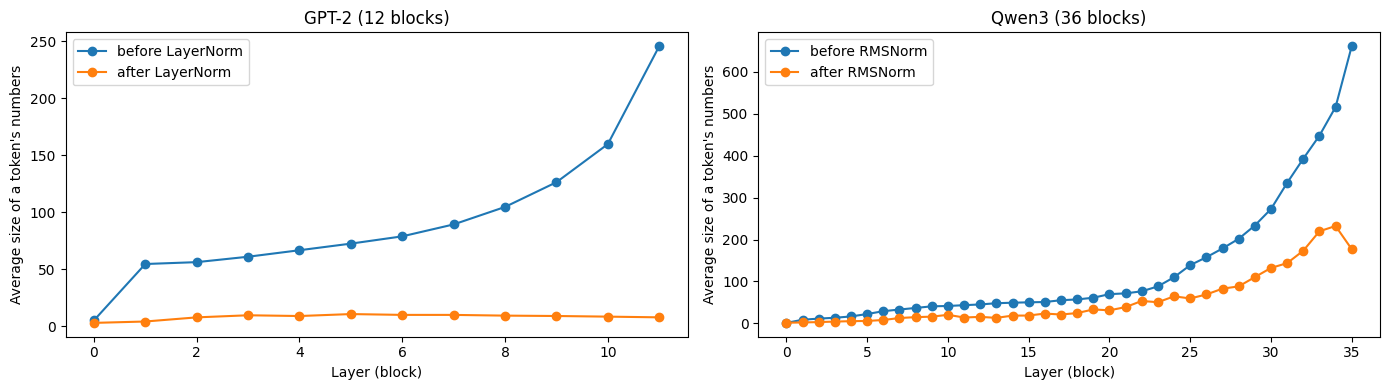

GPT-2: size before the norm grows 49x from the first block to the last; after the norm it stays between 2.9 and 10.6
Qwen3: size before the norm grows 668x from the first block to the last; after the norm it stays between 1.4 and 232.3
Qwen3 first token's size before the norm, every 5th block: [1, 108, 4351, 4352, 4569, 4567, 4571, 3659]


In [22]:
q_before, q_after, q_first = [], [], []

def make_rms_hook():
    def hook(module, inp, outp):
        b, a = inp[0][0].float(), outp[0].float()
        q_before.append(b[1:].norm(dim=-1).mean().item())    # average size, skipping the first token
        q_after.append(a[1:].norm(dim=-1).mean().item())
        q_first.append(b[0].norm().item())                   # first token measured separately
    return hook

hooks = [layer.input_layernorm.register_forward_hook(make_rms_hook()) for layer in qwen.model.layers]
with torch.no_grad():
    qwen(**q_enc)
for h in hooks:
    h.remove()

n_q = len(q_before)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(12), before, marker="o", label="before LayerNorm")
axes[0].plot(range(12), after, marker="o", label="after LayerNorm")
axes[0].set_title("GPT-2 (12 blocks)")
axes[1].plot(range(n_q), q_before, marker="o", label="before RMSNorm")
axes[1].plot(range(n_q), q_after, marker="o", label="after RMSNorm")
axes[1].set_title(f"Qwen3 ({n_q} blocks)")
for ax in axes:
    ax.set_xlabel("Layer (block)"); ax.set_ylabel("Average size of a token's numbers"); ax.legend()
plt.tight_layout(); plt.show()

print(f"GPT-2: size before the norm grows {before[-1] / before[0]:.0f}x from the first block to the last; after the norm it stays between {min(after):.1f} and {max(after):.1f}")
print(f"Qwen3: size before the norm grows {q_before[-1] / q_before[0]:.0f}x from the first block to the last; after the norm it stays between {min(q_after):.1f} and {max(q_after):.1f}")
print("Qwen3 first token's size before the norm, every 5th block:", [round(v) for v in q_first[::5]])

**What happens without the norms?** Same experiment as Section 3, in two versions:
1. remove the **72 block norms** (the one before attention and the one before feed-forward in every block), like we did with GPT-2's `ln_1` and `ln_2`;
2. remove only the **QK-Norm** inside attention.

Qwen3 is too big to copy on the T4, so instead of a copy we switch the norms off temporarily and put them back afterwards.

In [23]:
@contextmanager
def without_norms(block_norms=True, qk_norm=False):
    saved = []
    for layer in qwen.model.layers:
        saved.append((layer.input_layernorm, layer.post_attention_layernorm, layer.self_attn.q_norm, layer.self_attn.k_norm))
        if block_norms:
            layer.input_layernorm = torch.nn.Identity()
            layer.post_attention_layernorm = torch.nn.Identity()
        if qk_norm:
            layer.self_attn.q_norm = torch.nn.Identity()
            layer.self_attn.k_norm = torch.nn.Identity()
    try:
        yield
    finally:   # always put the norms back
        for layer, (a, b, q, k) in zip(qwen.model.layers, saved):
            layer.input_layernorm, layer.post_attention_layernorm = a, b
            layer.self_attn.q_norm, layer.self_attn.k_norm = q, k

def qwen_continue(prompt, n=20):
    enc = qwen_tok(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = qwen.generate(**enc, max_new_tokens=n, do_sample=False, pad_token_id=qwen_tok.eos_token_id)
    return qwen_tok.decode(out[0], skip_special_tokens=True)

prompt = "The people of Kicukiro say"
print(f"Loss with all norms:            {qwen_loss(english):.2f}")
print("   ", qwen_continue(prompt))
with without_norms(block_norms=True):
    print(f"Loss without the 72 block norms: {qwen_loss(english):.2f}")
    print("   ", qwen_continue(prompt))
with without_norms(block_norms=False, qk_norm=True):
    print(f"Loss without QK-Norm only:       {qwen_loss(english):.2f}")
    print("   ", qwen_continue(prompt))
print(f"\nCheck, norms back in place:      {qwen_loss(english):.2f}")

Loss with all norms:            3.67
    The people of Kicukiro say that the name "Kicukiro" means "the place where the river flows." This is
Loss without the 72 block norms: nan
    The people of Kicukiro say!!!!!!!!!!!!!!!!!!!!
Loss without QK-Norm only:       12.09
    The people of Kicukiro say  \"aaaaaaaana""""„●••****ammerps \\\::\

Check, norms back in place:      3.67


### 10.7 Attention: grouped-query attention (GQA)
In GPT-2 each of the 12 heads has its **own** queries, keys and values. Qwen3 has **32 query heads** but only **8 key-value heads**: every 4 query heads share one set of keys and values. This saves a lot of memory when generating long texts, with little loss in quality.

The size of the weight matrices shows it:

In [24]:
attn0 = qwen.model.layers[0].self_attn
head_dim = qcfg.head_dim if getattr(qcfg, "head_dim", None) else qcfg.hidden_size // qcfg.num_attention_heads
print(f"Each head works with {head_dim} numbers")
print(f"Query weights: {tuple(attn0.q_proj.weight.shape)} -> {attn0.q_proj.weight.shape[0] // head_dim} query heads")
print(f"Key weights:   {tuple(attn0.k_proj.weight.shape)} -> {attn0.k_proj.weight.shape[0] // head_dim} key heads")
print(f"Value weights: {tuple(attn0.v_proj.weight.shape)} -> {attn0.v_proj.weight.shape[0] // head_dim} value heads")
print(f"So {qcfg.num_attention_heads // qcfg.num_key_value_heads} query heads share each key-value head.")

Each head works with 128 numbers
Query weights: (4096, 2560) -> 32 query heads
Key weights:   (1024, 2560) -> 8 key heads
Value weights: (1024, 2560) -> 8 value heads
So 4 query heads share each key-value head.


Same search as Section 4: which heads look at the **previous token**, and which act as an **attention sink** on the first token? Qwen3 has 36 × 32 = 1,152 heads to check.

36 layers x 32 heads, sentence of 17 tokens

Qwen3 heads that look at the PREVIOUS token:
  Layer 0, Head 1: 0.8722
  Layer 1, Head 4: 0.8268
  Layer 19, Head 20: 0.8069

Qwen3 heads that look at the FIRST token (attention sink):
  Layer 13, Head 12: 1.0000
  Layer 20, Head 24: 0.9998
  Layer 7, Head 6: 0.9996

Heads putting more than 90% of their attention on the first token: Qwen3 367 of 1152, GPT-2 31 of 144


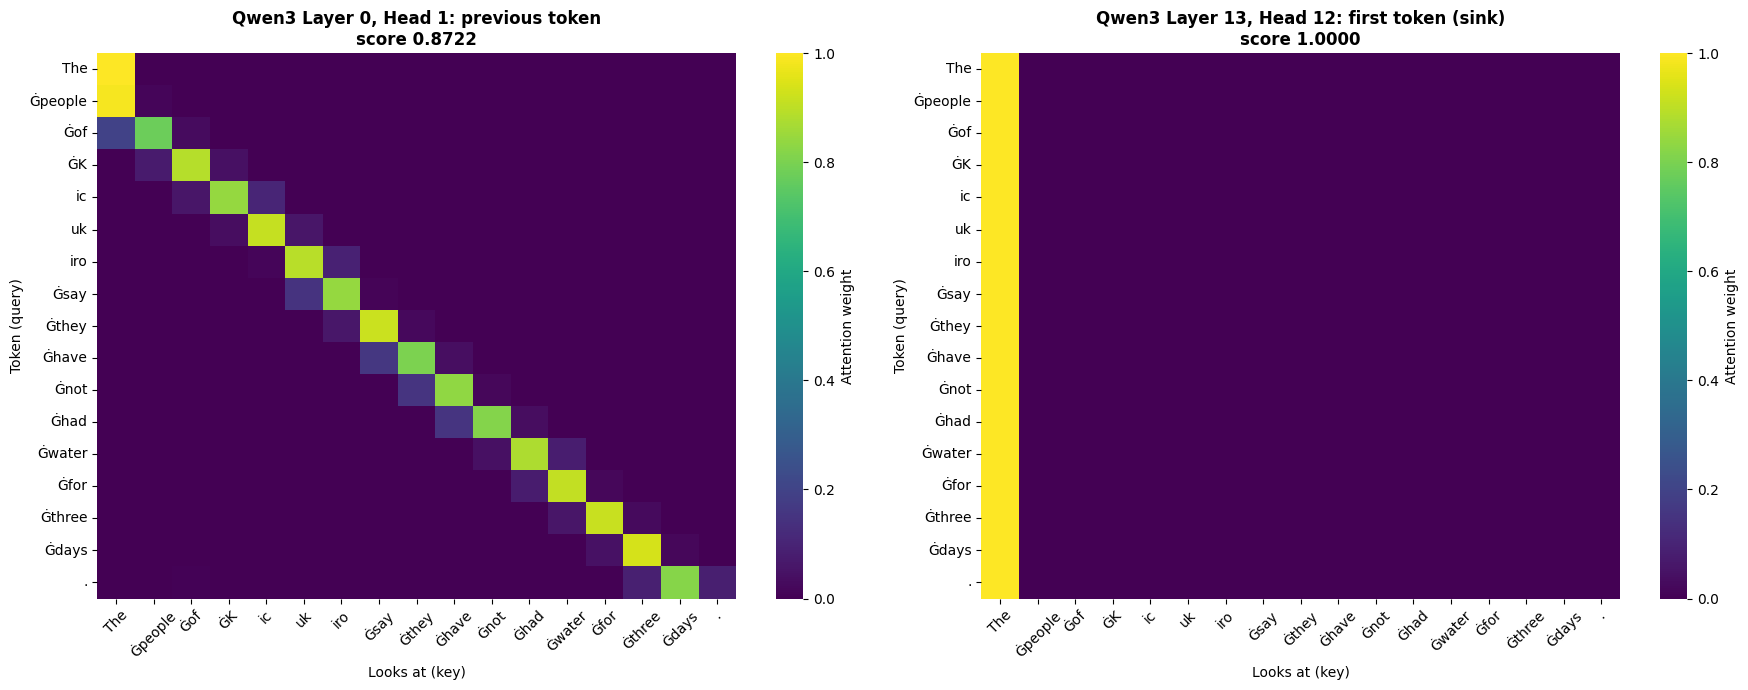

In [25]:
with torch.no_grad():
    q_attn = qwen(**q_enc, output_attentions=True).attentions
q_tokens = qwen_tok.convert_ids_to_tokens(q_enc["input_ids"][0])
print(f"{len(q_attn)} layers x {q_attn[0].shape[1]} heads, sentence of {len(q_tokens)} tokens\n")

q_prev, q_sink = [], []
for layer in range(len(q_attn)):
    layer_attn = q_attn[layer][0].float().cpu().numpy()
    for head in range(layer_attn.shape[0]):
        m = layer_attn[head]
        q_prev.append((np.mean([m[i, i - 1] for i in range(1, q_n)]), layer, head))
        q_sink.append((np.mean(m[1:, 0]), layer, head))
q_prev.sort(reverse=True); q_sink.sort(reverse=True)

print("Qwen3 heads that look at the PREVIOUS token:")
for score, layer, head in q_prev[:3]:
    print(f"  Layer {layer}, Head {head}: {score:.4f}")
print("\nQwen3 heads that look at the FIRST token (attention sink):")
for score, layer, head in q_sink[:3]:
    print(f"  Layer {layer}, Head {head}: {score:.4f}")
sink_heads = sum(1 for s, _, _ in q_sink if s > 0.9)
print(f"\nHeads putting more than 90% of their attention on the first token: Qwen3 {sink_heads} of {len(q_sink)}, "
      f"GPT-2 {sum(1 for s, _, _ in first_token_scores if s > 0.9)} of {len(first_token_scores)}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (score, layer, head), label in [(axes[0], q_prev[0], "previous token"), (axes[1], q_sink[0], "first token (sink)")]:
    sns.heatmap(q_attn[layer][0, head].float().cpu().numpy(), xticklabels=q_tokens, yticklabels=q_tokens,
                cmap="viridis", ax=ax, cbar_kws={"label": "Attention weight"})
    ax.set_title(f"Qwen3 Layer {layer}, Head {head}: {label}\nscore {score:.4f}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Looks at (key)"); ax.set_ylabel("Token (query)")
    ax.tick_params(axis="x", rotation=45); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()
del q_attn

### 10.8 Predicting the next word: GPT-2 vs Qwen3
Same test as Section 9, side by side. The correct next words are **" days"** and **" mazi"** ("water").

In [26]:
def top_next_tokens(m, tok, prompt, k=5):
    enc = tok(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = F.softmax(m(**enc).logits[0, -1].float(), dim=-1)
    top_p, top_i = torch.topk(probs, k)
    return [f"{tok.decode(i)!r} {p.item():.1%}" for p, i in zip(top_p, top_i)], probs

for prompt, correct in [("The people of Kicukiro say they have not had water for three", " days"),
                        ("Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta", " mazi")]:
    g_top, g_probs = top_next_tokens(model, tokenizer, prompt)
    q_top, q_probs = top_next_tokens(qwen, qwen_tok, prompt)
    g_ok = g_probs[tokenizer.encode(correct)[0]].item()
    q_ok = q_probs[qwen_tok.encode(correct)[0]].item()
    print(f"Prompt: '{prompt}'   (correct: {correct!r})")
    display(pd.DataFrame({"GPT-2 top 5": g_top, "Qwen3 top 5": q_top}))
    print(f"Chance of the correct word's first token: GPT-2 {g_ok:.1%} | Qwen3 {q_ok:.1%}\n")

Prompt: 'The people of Kicukiro say they have not had water for three'   (correct: ' days')


,GPT-2 top 5,Qwen3 top 5
0,' years' 34.1%,' days' 62.7%
1,' months' 26.1%,' months' 13.4%
2,' days' 18.0%,' weeks' 12.0%
3,' weeks' 11.0%,' years' 8.8%
4,' or' 3.1%,' or' 1.3%


Chance of the correct word's first token: GPT-2 18.0% | Qwen3 62.7%

Prompt: 'Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta'   (correct: ' mazi')


,GPT-2 top 5,Qwen3 top 5
0,' k' 4.8%,' b' 9.0%
1,' b' 4.0%,' k' 7.8%
2,' n' 3.1%,' m' 7.4%
3,' m' 1.9%,"',' 4.2%"
4,' a' 1.5%,' na' 1.9%


Chance of the correct word's first token: GPT-2 1.9% | Qwen3 7.4%



**Next-word demo:** type the start of a sentence and see both models' top 5 guesses for the next word, side by side. It shows *how* each model predicts, one word at a time. Like the chat demo below, it only works while this cell is running (in a saved notebook the old window shows *502 Bad Gateway*).

In [27]:
!pip install -q gradio
import gradio as gr

def next_words(prompt):
    g_top, _ = top_next_tokens(model, tokenizer, prompt)
    q_top, _ = top_next_tokens(qwen, qwen_tok, prompt)
    return pd.DataFrame({"GPT-2 top 5": g_top, "Qwen3 top 5": q_top})

gr.Interface(
    fn=next_words,
    inputs=gr.Textbox(label="Start of a sentence (English or Kinyarwanda)",
                      value="The people of Kicukiro say they have not had water for three"),
    outputs=gr.Dataframe(label="Next-word guesses"),
    title="Group 1: next-word predictor, GPT-2 vs Qwen3",
).launch(share=True)

(Demo output removed: this demo only works while the cell is running in a live Colab session.)


### 10.9 Asking a question: continuing text vs following instructions
GPT-2 can only continue text, so a question just gets continued. Qwen3 was trained to follow instructions, so we send the question through its **chat template**, which marks it as a user message and asks the model to answer.

In [ ]:
def gpt2_continue(prompt, n=60):
    # GPT-2 can only continue text (same as continue_text in Section 3)
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=n, do_sample=False, pad_token_id=tokenizer.eos_token_id,
                             output_attentions=False, output_hidden_states=False)
    return tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def qwen_chat(question, max_new_tokens=150, system=None):
    # system = an optional instruction the model reads first (for example, who it is)
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": question}]
    text = qwen_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    enc = qwen_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = qwen.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=qwen_tok.eos_token_id)
    return qwen_tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

QWEN_IDENTITY = ("You are Qwen3, an AI model made by the Qwen team at Alibaba Cloud, "
                 "used here in Group 1's class project.")

questions = [
    "Why do some neighbourhoods in Kigali go several days without water? Answer in 3 short sentences.",
    "Kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite? Subiza mu Kinyarwanda, mu nteruro 3.",
]
for q in questions:
    print("QUESTION:", q)
    print("\nGPT-2:", gpt2_continue(q))
    print("\nQwen3:", qwen_chat(q))
    print("\n" + "=" * 90 + "\n")

### 10.10 Chat demo with Qwen3
A simple web chat, like our GPT-2 demo, but now with a model that answers questions. Run the cell, then type in the box (or open the public link it prints). The cell keeps the demo running until you stop it.

**Note:** the demo only works while this cell is running. In a saved notebook the old demo window shows *502 Bad Gateway*, because the session that ran it has stopped. To use it again, run the first setup cell, then 10.1, 10.9 and this cell (10.9 now works on its own).

**Who is answering?** A model doesn't know who it is: asked *"who are you?"*, it writes the answer that was most likely in its training data, which can be another company's AI. So the chat box sends a **system message** first, saying which model it is and who made it (prompt engineering).

In [ ]:
!pip install -q gradio
import gradio as gr

def respond(message, history):
    return qwen_chat(message, system=QWEN_IDENTITY)

gr.ChatInterface(
    respond,
    title="Group 1: chat with Qwen3-4B",
    description="Ask a question in English or Kinyarwanda.",
).launch(share=True)

### What we found: GPT-2 vs Qwen3
*(Filled in from this notebook's outputs, run on a Colab T4 GPU.)*

| | GPT-2 small | Qwen3-4B-Instruct-2507 |
|---|---|---|
| Parameters | 124 million | 4,022 million (32× bigger) |
| Weights in memory | 0.50 GB | 8.04 GB (8.6 GB of the T4's 15.6 GB in use) |
| Speed | 79.9 tokens/second | 7.1 tokens/second (11.2× slower) |
| Kinyarwanda tokens per word | 2.42 | 2.25 |
| Loss per word, English | 5.48 | **4.51** |
| Loss per word, Kinyarwanda | 17.15 | **14.92** |
| Chance of " days" as the next word | 18.0% | **62.7%** |

1. **Speed and memory:** Qwen3 fits on the free T4 with room to spare (8.6 GB of 15.6 GB), but it is much slower than GPT-2: **7.1 tokens per second** in this run, 11.2× slower. Speed changes between Colab sessions: in an earlier run on another T4 it wrote 15.2 tokens per second. Either way it is fast enough for a short chat answer.
2. **Tokens:** Qwen3's bigger vocabulary helps only a little with Kinyarwanda: **2.25 tokens per word** instead of 2.42 (1.59× as many tokens as English instead of 1.71×). "iminsi" becomes 2 pieces instead of 3, but "amazi", "itatu" and "bavuga" are split exactly like in GPT-2.
3. **Loss:** Qwen3 predicts both sentences better than GPT-2 (per word: English 4.51 vs 5.48, Kinyarwanda 14.92 vs 17.15). But Kinyarwanda is still more than **3× harder** than English for Qwen3.
4. **Position:** Qwen3 has **no position table**; it uses RoPE (base 5,000,000, up to 262,144 positions). Scrambling the positions still hurts: its loss goes from 3.67 to 6.24 on average (GPT-2: 4.46 to 9.75). Both models depend on word order.
5. **Layer norm → RMSNorm (my part):**
    - Qwen3 has **145 RMSNorms** (36 blocks × 4, plus a final one), against GPT-2's 25 LayerNorms.
    - The numbers going into the norm grow much more than in GPT-2: about **668×** from the first block to the last (GPT-2: 49×). The first token grows to over 4,000, the same "attention sink" pattern we saw in GPT-2.
    - After RMSNorm the numbers are much smaller, but they are **not flat** like after GPT-2's LayerNorm: they rise in the last blocks (up to about 230). RMSNorm brings each token to a standard size, then multiplies by **learned weights**, and Qwen3 learned bigger weights in its deeper blocks.
    - **Removing the 72 block norms breaks Qwen3 completely**, exactly like GPT-2: the loss becomes `nan` and it writes only "!!!!!". **Removing only QK-Norm** also breaks it: the loss jumps from 3.67 to 12.09 and the text becomes nonsense. So QK-Norm isn't optional: Qwen3 was trained with it and depends on it.
6. **Attention:** Qwen3 really uses **grouped-query attention**: 32 query heads share 8 key-value heads (4 queries per key-value head). It has the same kinds of specialised heads as GPT-2: a previous-token head (Layer 0, Head 1, 0.87) and attention sinks. Sinks are much more common: **367 of 1,152 heads** (32%) put over 90% of their attention on the first token, against 31 of 144 (22%) in GPT-2.
7. **Next word and chat:**
    - **English:** Qwen3 is clearly better. It picks **" days"** as its top guess (62.7%), where GPT-2 preferred " years" (18.0% for " days"). Asked a question, Qwen3 gives a clear 3-sentence answer; GPT-2 just continues the text with made-up facts.
    - **Kinyarwanda: Qwen3 is still weak.** Its chance of the right next word's first piece is only 7.4% (GPT-2: 1.9%), and when asked our Kinyarwanda question it **repeated the question with made-up words instead of answering**. This confirms the risk in our blog: Qwen3 doesn't really speak Kinyarwanda, so a Kinyarwanda model like **Sunflower** (built on Qwen) is the next step.

**In short:** Qwen3 fixes GPT-2's English problems (it answers questions and predicts much better) and runs on a free T4, but it does not fix the Kinyarwanda problem.

### Sources for Section 10
- Qwen3-4B-Instruct-2507 model card: https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507
- Qwen Team (2025). *Qwen3 Technical Report.* https://arxiv.org/abs/2505.09388
- Zhang & Sennrich (2019). *Root Mean Square Layer Normalization.* https://arxiv.org/abs/1910.07467
- Su et al. (2021). *RoFormer: Enhanced Transformer with Rotary Position Embedding.* https://arxiv.org/abs/2104.09864
- Ainslie et al. (2023). *GQA: Training Generalized Multi-Query Transformer Models.* https://arxiv.org/abs/2305.13245


### 10.11 RAG with Qwen3: giving the model real documents

When we asked Qwen3 *"What are the universities in Rwanda?"*, it named the University of Rwanda and then **invented** universities that don't exist. This is called **hallucination**: the model has no real list, so it fills the gap with names that sound right.

**RAG (Retrieval-Augmented Generation)** fixes this by letting the model read real documents before it answers:

1. **We give the documents.** RAG does not search the internet. It only knows what we put in the list below.
2. **Each document is turned into numbers** (an *embedding*) that capture its meaning.
3. **The question is turned into numbers the same way.**
4. **The closest documents are picked** (highest *cosine similarity*), here the top 3.
5. **They are pasted into the prompt** with the rule: *answer only from these documents, otherwise say you don't know.*
6. **The model answers.**

**What RAG fixes:** missing or invented facts. **What it does not fix:** language skill. A model that writes poor Kinyarwanda still writes poor Kinyarwanda, even with the right documents.

Here Qwen3 writes the answers. In Section 12 we give the same documents to Sunflower.

**Our documents**

The university lists come from the **Higher Education Council (HEC)**, *Contact List for all Institutions (2025)*. The other documents are about the models we use, so the search has to choose between topics. You can add your own documents to this list: one short paragraph each, with its source.

In [ ]:
documents = [
    {"source": "HEC Rwanda, Contact List for all Institutions (2025)",
     "text": "Public higher learning institutions in Rwanda accredited by the Higher Education Council (HEC): "
             "University of Rwanda (UR), Rwanda Polytechnic (RP), and the Institute of Legal Practice and Development (ILPD)."},
    {"source": "HEC Rwanda, Contact List for all Institutions (2025)",
     "text": "Private higher learning institutions in Rwanda (part 1): Independent University of Kigali (ULK), "
             "Institute of Lay Adventists of Kigali (INILAK), Catholic University of Rwanda (CUR), "
             "Adventist University of Central Africa (AUCA), Institut Catholique de Kabgayi (ICK), "
             "INES Ruhengeri, Institut Polytechnique de Byumba (IPB), Rwanda Tourism University College (RTUC), "
             "Institut Superieur Pedagogique de Gitwe (ISPG), Protestant Institute of Arts and Social Sciences (PIASS), "
             "Mount Kigali University (MKU), Kibogora Polytechnic (KP), Carnegie Mellon University Africa (CMUA), "
             "University of Kigali (UoK), East African University Rwanda (EAUR), "
             "Ruli Higher Institute of Health Sainte Rose de Lima (RHIH), University of Global Health Equity (UGHE)."},
    {"source": "HEC Rwanda, Contact List for all Institutions (2025)",
     "text": "Private higher learning institutions in Rwanda (part 2): African Institute of Mathematical Sciences (AIMS Rwanda), "
             "African Leadership University (ALU), College of Surgeons of East, Central and Southern Africa, "
             "VATEL School Rwanda, Oklahoma Christian University (OCU), Rwanda Institute of Conservation Agriculture (RICA), "
             "African College of Theology (ACT), East African Christian College (EACC), Kepler College, "
             "Hanika Anglican Integrated Polytechnic (HAIP), Muhabura Integrated Polytechnic College (MIPC), "
             "Saint Joseph Integrated Technical College (SJITC Nyamirambo), ULK Polytechnic Institute, "
             "Africa Health Sciences University (AFU), University of Medical Science and Technology (UMST, cross border), "
             "African School of Governance (ASG)."},
    {"source": "HEC Rwanda website, Accredited institutions",
     "text": "The Higher Education Council (HEC) is the body that accredits universities and other higher learning "
             "institutions in Rwanda. Its office is in the Ministry of Education building in Kigali. "
             "Students are advised to check that an institution is accredited by HEC before enrolling."},
    {"source": "Sunflower model card, Hugging Face",
     "text": "Sunflower is a language model made by Sunbird AI in Uganda. It is built on Qwen and trained further on "
             "African languages, including Kinyarwanda. The version used in this project has about 9.4 billion "
             "parameters and is stored in 4-bit so it fits on a free Colab T4 GPU."},
    {"source": "Qwen3-4B-Instruct-2507 model card, Hugging Face",
     "text": "Qwen3-4B-Instruct-2507 is a 4-billion-parameter chat model made by the Qwen team at Alibaba Cloud. "
             "It answers well in English but was trained on very little Kinyarwanda."},
    {"source": "Radford et al. (2019), Language Models are Unsupervised Multitask Learners",
     "text": "GPT-2 is a language model released by OpenAI in 2019. The small version has 124 million parameters. "
             "It only predicts the next word and was not trained to follow instructions or chat."},
]
print(f"{len(documents)} documents ready.")

**The search model (embeddings)**

We use **BGE-M3**, a free multilingual embedding model (about 1 GB on the GPU in half precision). It turns each document and each question into 1,024 numbers. Similar meanings get similar numbers, even across languages, so a Kinyarwanda question can find an English document. We are not sure how well it knows Kinyarwanda, so the next cell checks which documents it picks.

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("BAAI/bge-m3", device=device)
if device == "cuda":
    embedder.half()

doc_vectors = embedder.encode([d["text"] for d in documents],
                              normalize_embeddings=True, convert_to_tensor=True)
print("Document vectors:", tuple(doc_vectors.shape), "(documents x numbers per document)")
if device == "cuda":
    print(f"GPU memory used now: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

def retrieve(question, k=3):
    # Return the k documents closest in meaning to the question, with their scores.
    q = embedder.encode([question], normalize_embeddings=True, convert_to_tensor=True)
    scores = (doc_vectors @ q.T).squeeze(1)   # cosine similarity (vectors have length 1)
    top = torch.topk(scores, k)
    return [(documents[int(i)], float(s)) for s, i in zip(top.values, top.indices)]

RAG_RULES = ("Answer the question using only the documents below. "
             "If the answer is not in the documents, say that you don't know. "
             "Answer in the same language as the question.")

def rag_messages(question, identity, k=3):
    # Build the chat messages: who the model is + the rules, then the top k documents + the question.
    found = retrieve(question, k)
    context = "\n\n".join(f"[Document {n + 1}] {doc['text']}" for n, (doc, _) in enumerate(found))
    messages = [{"role": "system", "content": identity + " " + RAG_RULES},
                {"role": "user", "content": f"Documents:\n{context}\n\nQuestion: {question}"}]
    sources = sorted({doc["source"] for doc, _ in found})
    return messages, sources

rag_questions = [
    "What are the universities in Rwanda?",
    "Ni izihe kaminuza za Leta ziri mu Rwanda?",
    "Who won the Tour du Rwanda in 2026?",   # not in our documents
]

**Does the search pick the right documents?**

Score = cosine similarity: closer to 1 means closer in meaning. The university documents should come first for the university questions, in both languages, and the Sunflower document for the last one.

In [ ]:
for q in rag_questions[:2] + ["Who made the Sunflower model?"]:
    print("QUESTION:", q)
    for doc, score in retrieve(q):
        print(f"   {score:.3f}  {doc['text'][:80]}...")
    print()

### 10.12 Qwen3 with and without RAG
The same questions, first without documents, then with the top 3 documents in the prompt. The last question is **not** in our documents, so a good RAG answer should say it doesn't know. The answers are saved, so Section 12 can compare them with Sunflower after Qwen3 is removed.

In [ ]:
def qwen_rag_answer(question, max_new_tokens=400):
    messages, sources = rag_messages(question, QWEN_IDENTITY)
    text = qwen_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    enc = qwen_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = qwen.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=qwen_tok.eos_token_id)
    answer = qwen_tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return answer, sources

rag_saved = {}
for q in rag_questions:
    alone = qwen_chat(q, max_new_tokens=400)
    with_rag, sources = qwen_rag_answer(q)
    rag_saved[q] = {"Qwen3 alone": alone, "Qwen3 + RAG": with_rag, "sources": sources}
    print("QUESTION:", q)
    print("\nQwen3 alone:", alone)
    print("\nQwen3 + RAG:", with_rag)
    print("Sources:    ", "; ".join(sources))
    print("\n" + "=" * 90 + "\n")

### 10.13 RAG chat box with Qwen3
Like 10.10, but every answer uses our documents and lists its sources. It only works while Qwen3 is loaded, so use it **before** running Section 11.

In [ ]:
def respond_qwen_rag(message, history):
    answer, sources = qwen_rag_answer(message)
    return answer + "\n\nSources: " + "; ".join(sources)

gr.ChatInterface(
    respond_qwen_rag,
    title="Group 1: Qwen3 + RAG",
    description="Ask in English or Kinyarwanda about universities in Rwanda.",
).launch(share=True)

### What we found: does RAG help Qwen3?
*(Fill in from this notebook's outputs.)*

1. **Search (10.11):** did the right documents come first, for both the English and the Kinyarwanda question? ___
2. **Qwen3 alone (10.12):** did it list real universities, or invent some? ___
3. **Qwen3 + RAG (10.12):** were the names correct? Was the Kinyarwanda answer in real Kinyarwanda? ___
4. **Question not in the documents:** did it say it doesn't know? ___

### Sources for the RAG part

- Higher Education Council (HEC) Rwanda, Accredited institutions: https://www.hec.gov.rw/accredited-institutions
- HEC Rwanda, Contact List for all Institutions (2025): https://www.hec.gov.rw/fileadmin/user_upload/HEC/Accreditation/Heads_of_HLIs_operating_in_Rwanda_2025.pdf
- BGE-M3 embedding model: https://huggingface.co/BAAI/bge-m3
- Lewis et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* https://arxiv.org/abs/2005.11401

## 11. Does Sunflower fix Kinyarwanda?

Section 10 showed that Qwen3 answers well in English but **not in Kinyarwanda**. In our blog, the next step was **Sunflower**, a model from **Sunbird AI** (Uganda) built on Qwen and trained further on **African languages, including Kinyarwanda**.

We use **`Sunbird/Sunflower-Qwen3.5-9B-bnb-4bit`**:
- **9.4 billion parameters**, built on Qwen3.5-9B and trained to understand 67 African languages
- compressed to **4-bit**, so it fits on a free T4 (7.9 GB). Without compression it would need about 19 GB.
- free to download, no account needed
- a **preview** release: Sunbird may still update it, so results can change later

**Important:** Sunflower and Qwen3 don't both fit on the T4 at the same time. So we first **save Qwen3's results**, then remove Qwen3 from memory and load Sunflower. Run Section 10 before this section.

Sunflower is also **slower**: it is bigger, its 4-bit weights are unpacked as it runs, and some of its layers use a newer kind of attention that runs without its fast code on Colab. Expect a few minutes for this section.

### 11.1 Save Qwen3's results, then free the GPU
We ask Qwen3 the same questions we will ask Sunflower (plus two translations), keep its answers and next-word guesses, and then remove it from the GPU. The search model and documents from 10.11 stay loaded.

In [30]:
translations = [
    "Translate to Kinyarwanda: " + english,
    "Translate to English: " + kinyarwanda,
]
sun_questions = questions + translations
next_prompts = [("The people of Kicukiro say they have not had water for three", " days"),
                ("Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta", " mazi")]

qwen_saved = {"answers": {}, "next": {}}
for q in sun_questions:
    qwen_saved["answers"][q] = qwen_chat(q)
for prompt, correct in next_prompts:
    top, probs = top_next_tokens(qwen, qwen_tok, prompt)
    qwen_saved["next"][prompt] = (top, probs[qwen_tok.encode(correct)[0]].item())
print("Saved Qwen3's answers and next-word guesses.")

del qwen
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
    print(f"GPU memory in use after removing Qwen3: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Saved Qwen3's answers and next-word guesses.
GPU memory in use after removing Qwen3: 0.7 GB


### 11.2 Loading Sunflower
The 4-bit settings are already saved inside the model, so we only need to install `bitsandbytes`, the library that runs 4-bit models.

In [ ]:
!pip install -q bitsandbytes
import json
from huggingface_hub import hf_hub_download
from transformers import AutoModelForImageTextToText, AutoProcessor

SUN_NAME = "Sunbird/Sunflower-Qwen3.5-9B-bnb-4bit"
sun = AutoModelForImageTextToText.from_pretrained(SUN_NAME, device_map=device).eval()
sun_tok = AutoProcessor.from_pretrained(SUN_NAME).tokenizer

sun_params = json.load(open(hf_hub_download(SUN_NAME, "model.safetensors.index.json")))["metadata"]["total_parameters"]
print(f"Sunflower loaded: {sun_params / 1e9:.1f} billion parameters, stored in 4-bit")
print(f"Vocabulary: {len(sun_tok):,} tokens (Qwen3: {len(qwen_tok):,}, GPT-2: {len(tokenizer):,})")
if device == "cuda":
    print(f"GPU memory used now: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

def sun_loss(text):
    enc = sun_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        return sun(**enc, labels=enc["input_ids"]).loss.item()

SUN_IDENTITY = ("You are Sunflower, an AI model made by Sunbird AI in Uganda, "
                "used here in Group 1's class project. You can answer in Kinyarwanda and English.")

def sun_chat(question, max_new_tokens=150, system=None):
    # system = an optional instruction the model reads first (for example, who it is)
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": question}]
    enc = sun_tok.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False,
                                      return_tensors="pt", return_dict=True).to(device)
    with torch.no_grad():
        out = sun.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
    return sun_tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

### 11.3 Tokens
Does Sunflower cut Kinyarwanda into fewer pieces? Sunflower kept the tokenizer of the model it was built on (Qwen3.5), so this shows whether that tokenizer is better for Kinyarwanda than Qwen3's.

In [32]:
rows = []
for name, s in [("English", english), ("Kinyarwanda", kinyarwanda)]:
    w = len(s.split())
    rows.append({"language": name, "words": w,
                 "GPT-2 tokens per word": round(len(tokenizer.encode(s)) / w, 2),
                 "Qwen3 tokens per word": round(len(qwen_tok.encode(s)) / w, 2),
                 "Sunflower tokens per word": round(len(sun_tok.encode(s)) / w, 2)})
display(pd.DataFrame(rows))

print(f"\n{'word':>8} | {'Qwen3':<22} | Sunflower")
for w in ["amazi", "itatu", "iminsi", "bavuga", "abaturage"]:
    print(f"{w:>8} | {str(qwen_tok.tokenize(' ' + w)):<22} | {sun_tok.tokenize(' ' + w)}")

,language,words,GPT-2 tokens per word,Qwen3 tokens per word,Sunflower tokens per word
0,English,13,1.31,1.31,1.31
1,Kinyarwanda,12,2.42,2.25,2.17



    word | Qwen3                  | Sunflower
   amazi | ['Ġam', 'azi']         | ['Ġam', 'azi']
   itatu | ['Ġit', 'atu']         | ['Ġit', 'atu']
  iminsi | ['Ġim', 'insi']        | ['Ġim', 'insi']
  bavuga | ['Ġb', 'av', 'uga']    | ['Ġbav', 'uga']
abaturage | ['Ġab', 'atur', 'age'] | ['Ġab', 'atur', 'age']


### 11.4 Loss per word
Lower = the model is less surprised by the sentence. If Sunflower's Kinyarwanda training worked, its Kinyarwanda loss should drop a lot.

In [33]:
rows = []
for name, s in [("English", english), ("Kinyarwanda", kinyarwanda)]:
    w = len(s.split())
    prev = loss_table.set_index("language").loc[name]
    rows.append({"language": name,
                 "GPT-2 loss per word": prev["GPT-2 loss per word"],
                 "Qwen3 loss per word": prev["Qwen3 loss per word"],
                 "Sunflower loss per word": round(total_loss(sun_loss, sun_tok, s) / w, 2)})
sun_loss_table = pd.DataFrame(rows)
display(sun_loss_table)

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


,language,GPT-2 loss per word,Qwen3 loss per word,Sunflower loss per word
0,English,5.48,4.51,3.47
1,Kinyarwanda,17.15,14.92,3.22


### 11.5 Next word
The same two sentences. The correct next words are **" days"** and **" mazi"**.

In [34]:
sun_next = {}
for prompt, correct in next_prompts:
    g_top, g_probs = top_next_tokens(model, tokenizer, prompt)
    q_top, q_ok = qwen_saved["next"][prompt]
    s_top, s_probs = top_next_tokens(sun, sun_tok, prompt)
    s_ok = s_probs[sun_tok.encode(correct)[0]].item()
    sun_next[prompt] = s_ok
    print(f"Prompt: '{prompt}'   (correct: {correct!r})")
    display(pd.DataFrame({"GPT-2 top 5": g_top, "Qwen3 top 5": q_top, "Sunflower top 5": s_top}))
    print(f"Chance of the correct word's first token: GPT-2 {g_probs[tokenizer.encode(correct)[0]].item():.1%} | "
          f"Qwen3 {q_ok:.1%} | Sunflower {s_ok:.1%}\n")

Prompt: 'The people of Kicukiro say they have not had water for three'   (correct: ' days')


,GPT-2 top 5,Qwen3 top 5,Sunflower top 5
0,' years' 34.1%,' days' 62.7%,' days' 43.7%
1,' months' 26.1%,' months' 13.4%,' weeks' 23.4%
2,' days' 18.0%,' weeks' 12.0%,' months' 23.4%
3,' weeks' 11.0%,' years' 8.8%,' years' 7.6%
4,' or' 3.1%,' or' 1.3%,' consecutive' 0.6%


Chance of the correct word's first token: GPT-2 18.0% | Qwen3 62.7% | Sunflower 43.7%

Prompt: 'Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta'   (correct: ' mazi')


,GPT-2 top 5,Qwen3 top 5,Sunflower top 5
0,' k' 4.8%,' b' 9.0%,' m' 63.8%
1,' b' 4.0%,' k' 7.8%,' muy' 16.1%
2,' n' 3.1%,' m' 7.4%,' mv' 3.6%
3,' m' 1.9%,"',' 4.2%",' mash' 2.5%
4,' a' 1.5%,' na' 1.9%,' mus' 2.5%


Chance of the correct word's first token: GPT-2 1.9% | Qwen3 7.4% | Sunflower 63.8%



### 11.6 Questions and translation
The two questions from Section 10.9, plus a translation in each direction (translation is what Sunflower was trained on most). Qwen3's answers were saved in 11.1.

In [35]:
for q in sun_questions:
    print("QUESTION:", q)
    print("\nQwen3:    ", qwen_saved["answers"][q])
    print("\nSunflower:", sun_chat(q))
    print("\n" + "=" * 90 + "\n")

QUESTION: Why do some neighbourhoods in Kigali go several days without water? Answer in 3 short sentences.

Qwen3:     Some neighborhoods in Kigali experience water shortages due to aging infrastructure and uneven distribution of the water supply network. The city's water system struggles to meet demand, especially during peak hours or in areas with poor pipe maintenance. Additionally, maintenance and repair work are often delayed, leading to prolonged outages in certain zones.


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.



Sunflower: Some neighborhoods in Kigali lack water for several days because of maintenance on the main supply lines. Residents often rely on buckets and buckets to fetch water from distant sources. The city authority has promised to fix the leaks and restore service soon.


QUESTION: Kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite? Subiza mu Kinyarwanda, mu nteruro 3.

Qwen3:     Ntare muzwa moko, kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite?  

**Subiza mu Kinyarwanda:**  
Kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite?  

**Nteruro 3:**  
Kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite?  

**Mizwa moko:**  
Ntare muzwa moko, kuki abaturage bamwe bo mu Kigali bamara iminsi nta mazi bafite?  

**Mizwa m

Sunflower: Hari abaturage bamara iminsi nta mazi kubera imiyoboro yangiritse, ibura ry'amazi, cyangwa ibibazo by'ubuyobozi.


QUESTION: Translate to Kinyarwanda: The people of Kicukiro say they have not had water for 

### 11.7 Speed
How many tokens per second Sunflower writes, compared with GPT-2 and Qwen3 from Section 10.2. It writes 20 tokens here, because it is slow.

In [36]:
speed_sun = tokens_per_second(sun, sun_tok, english, n_new=20)
display(pd.DataFrame({"tokens per second": [speed_gpt2, speed_qwen, speed_sun]},
                     index=["GPT-2 small", "Qwen3-4B", "Sunflower-9B (4-bit)"]).round(2))
if device == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

,tokens per second
GPT-2 small,79.85
Qwen3-4B,7.10
Sunflower-9B (4-bit),4.59


Peak GPU memory: 8.8 GB


### 11.8 Kinyarwanda chat demo with Sunflower
A web chat like 10.10, now with Sunflower. Only works while this cell is running (in a saved notebook the old window shows *502 Bad Gateway*). The Qwen3 demo from 10.10 stops working after 11.1, because Qwen3 was removed from memory.

**Who is answering?** A model doesn't know who it is: asked *"who are you?"*, it writes the answer that was most likely in its training data, which can be another company's AI. So the chat box sends a **system message** first, saying which model it is and who made it (prompt engineering).

In [ ]:
!pip install -q gradio
import gradio as gr

def respond_sun(message, history):
    return sun_chat(message, system=SUN_IDENTITY)

gr.ChatInterface(
    respond_sun,
    title="Group 1: chat with Sunflower (Kinyarwanda)",
    description="Baza ikibazo mu Kinyarwanda cyangwa mu Cyongereza. Ask a question in Kinyarwanda or English.",
).launch(share=True)

### What we found: does Sunflower fix Kinyarwanda?
*(Filled in from this notebook's outputs, run on a Colab T4 GPU.)*

| | GPT-2 small | Qwen3-4B | Sunflower-9B (4-bit) |
|---|---|---|---|
| Kinyarwanda tokens per word | 2.42 | 2.25 | 2.17 |
| Loss per word, English | 5.48 | 4.51 | **3.47** |
| Loss per word, Kinyarwanda | 17.15 | 14.92 | **3.22** |
| Chance of " days" (first piece) | 18.0% | **62.7%** | 43.7% |
| Chance of " mazi" (first piece, " m") | 1.9% | 7.4% | **63.8%** |
| Speed | 79.9 tokens/s | 7.1 tokens/s | 4.6 tokens/s |
| GPU memory | 0.5 GB | 8.6 GB | 8.6 GB (peak 8.8 GB) |

1. **Tokens:** Sunflower kept its base model's tokenizer, so Kinyarwanda is still cut into many pieces: **2.17 tokens per word**, only a little better than Qwen3 (2.25). "amazi", "itatu" and "iminsi" are split exactly like in Qwen3. Sunflower's improvement doesn't come from better tokens.
2. **Loss:** this is the big change. Sunflower's Kinyarwanda loss per word drops from **14.92 (Qwen3) to 3.22**, now even **lower than its English loss (3.47)**. It predicts our Kinyarwanda sentence about as easily as an English one, while for GPT-2 and Qwen3 it was more than 3× harder. (This is one sentence, so it shows the direction, not an exact score.)
3. **Next word:** for "...itatu nta", Sunflower gives **63.8%** to " m" (the start of "mazi"), against 7.4% for Qwen3 and 1.9% for GPT-2, and all its top 5 guesses start with "m". In English, Qwen3 is still a bit more confident about " days" (62.7% vs 43.7%), but both put it first.
4. **Questions and translation:**
    - **Kinyarwanda question:** Qwen3 repeated the question with made-up words. Sunflower answered in real Kinyarwanda: *"Hari abaturage bamara iminsi nta mazi kubera imiyoboro yangiritse, ibura ry'amazi, cyangwa ibibazo by'ubuyobozi."* (damaged pipes, water shortage or management problems). But it wrote **one sentence, not the three we asked for**, so it follows instructions less closely.
    - **Translation English → Kinyarwanda:** Qwen3 wrote nonsense ("Bato ya Kicukiro obitaka bato bato bato..."). Sunflower wrote *"Abaturage bo muri Kicukiro bavuga ko bamaze iminsi itatu badafite amazi"*, a correct translation.
    - **Translation Kinyarwanda → English:** Qwen3 just copied the Kinyarwanda sentence. Sunflower wrote *"Residents of Kicukiro have been without water for three days"*: the meaning is right, but it dropped "say".
    - **English question:** both answer well, but Sunflower adds details we never gave it ("The city authority has promised to fix the leaks"), which is a made-up claim (hallucination). Qwen3's English answer stays more general.
5. **Speed and memory:** Sunflower fits on the free T4 in 4-bit (8.6 GB, the same as Qwen3 in 16-bit), but it is the slowest: **4.6 tokens per second**, because it is bigger and its 4-bit weights are unpacked as it runs.
6. **Conclusion:** **Sunflower fixes the Kinyarwanda problem.** It predicts Kinyarwanda almost as well as English, answers in real Kinyarwanda and translates correctly, where Qwen3 failed every Kinyarwanda test. The trade-offs: it is slower, it followed our "3 sentences" instruction less well, it can add made-up details, and it is a preview release that may change. For our project, a good setup would be **Qwen3 for English and Sunflower for Kinyarwanda**, or Sunflower alone if Kinyarwanda matters most.

*Translations and Kinyarwanda answers should be checked by a Kinyarwanda speaker before we present them as correct.*

### Sources for Section 11
- Sunflower-Qwen3.5-9B-bnb-4bit (Sunbird AI): https://huggingface.co/Sunbird/Sunflower-Qwen3.5-9B-bnb-4bit
- Sunflower-Qwen3.5-9B model card: https://huggingface.co/Sunbird/Sunflower-Qwen3.5-9B
- Akera et al. (2026). *Sunflower: A New Approach to Expanding Coverage of African Languages in Large Language Models.* https://proceedings.mlr.press/v314/akera26a.html


### 11.9 Next-word guessing box with Sunflower

Type the start of a sentence and see Sunflower's top 5 next words. Like the other demos, it only works while the cell is running (in a saved notebook the old window shows *502 Bad Gateway*). The guesses are **tokens**, so sometimes you see half a word; the quotes show the spaces.

In [ ]:
import gradio as gr

def sun_next_words(text):
    enc = sun_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = sun(**enc).logits[0, -1]          # scores for the next token
    probs = torch.softmax(logits.float(), dim=-1)  # turn scores into chances
    top = torch.topk(probs, 5)                     # the 5 most likely
    return {repr(sun_tok.decode([int(i)])): float(p)
            for p, i in zip(top.values, top.indices)}

gr.Interface(
    fn=sun_next_words,
    inputs=gr.Textbox(label="Type the start of a sentence (Kinyarwanda or English)"),
    outputs=gr.Label(num_top_classes=5, label="Sunflower's top 5 next words"),
    title="Group 1: Sunflower guesses the next word",
    examples=["Abaturage bo mu Kicukiro bavuga ko bamaze iminsi itatu nta",
              "The people of Kicukiro say they have not had water for three"],
).launch(share=True)

## 12. RAG with Sunflower

Same documents and search as 10.11, but now **Sunflower** writes the answers. Qwen3's answers were saved in 10.12, so we can compare all four:

| | without RAG | with RAG |
|---|---|---|
| **Qwen3** | invents facts? | real facts, but weak Kinyarwanda? |
| **Sunflower** | invents facts? | real facts **and** good Kinyarwanda? |

Sunflower is slow (about 5 tokens per second), so the next cell takes several minutes.

### 12.1 All four answers

In [ ]:
def sun_rag_answer(question, max_new_tokens=400):
    messages, sources = rag_messages(question, SUN_IDENTITY)
    enc = sun_tok.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False,
                                      return_tensors="pt", return_dict=True).to(device)
    with torch.no_grad():
        out = sun.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
    answer = sun_tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return answer, sources

for q in rag_questions:
    sun_alone = sun_chat(q, max_new_tokens=400)
    sun_with_rag, sources = sun_rag_answer(q)
    print("QUESTION:", q)
    print("\nQwen3 alone:      ", rag_saved[q]["Qwen3 alone"])
    print("\nQwen3 + RAG:      ", rag_saved[q]["Qwen3 + RAG"])
    print("\nSunflower alone:  ", sun_alone)
    print("\nSunflower + RAG:  ", sun_with_rag)
    print("Sources:          ", "; ".join(sources))
    print("\n" + "=" * 90 + "\n")

### 12.2 RAG chat box with Sunflower
Like 11.8, but every answer uses our documents and lists its sources. Ask in Kinyarwanda or English. It only works while this cell is running.

In [ ]:
def respond_sun_rag(message, history):
    answer, sources = sun_rag_answer(message)
    return answer + "\n\nSources: " + "; ".join(sources)

gr.ChatInterface(
    respond_sun_rag,
    title="Group 1: Sunflower + RAG",
    description="Baza ikibazo mu Kinyarwanda cyangwa mu Cyongereza ku makaminuza yo mu Rwanda. "
                "Ask in Kinyarwanda or English about universities in Rwanda.",
).launch(share=True)

### What we found: Qwen3 vs Sunflower, with and without RAG
*(Fill in from this notebook's outputs.)*

| Question | Qwen3 alone | Qwen3 + RAG | Sunflower alone | Sunflower + RAG |
|---|---|---|---|---|
| Universities in Rwanda (English) | ___ | ___ | ___ | ___ |
| Public universities (Kinyarwanda) | ___ | ___ | ___ | ___ |
| Not in our documents | ___ | ___ | ___ | ___ |

1. **Does RAG stop made-up facts?** ___
2. **Does RAG fix Qwen3's Kinyarwanda?** ___
3. **Conclusion:** ___